# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:
1. Ми втратимо багатопоточність, бо розбиття на частини дозволяє нам обробляти дані паррельно. Зросте споживання оперативної пам'яті. Зникли б природні межі між віршами, які потім потрібні, щоб вставляти <eos> між творами.
2. Токенізація починається з нормалізації, під час якої сирий текст очищується та стандартизується. Далі на етапі пре-токенізації рядок грубо ділиться за пробілами й пунктуацією на окремі слова. Після цього модель розбиває кожне слово на оптимальні підслова згідно з вивченим словником і замінює їх на числові індекси. Насамкінець пост-обробка додає до числової послідовності службові маркери, формуючи фінальний масив даних для нейромережі.
3. Це зарезервовані службові токени, які токенізатор не розбиває на частини. Токен `<unk>` замінює відсутні у словнику елементи, а `<eos>` позначає кінець вірша.
4. Частка токенів unk залишається рівною нулю, оскільки ByteLevel BPE містить у базовому алфавіті всі 256 байтів UTF-8 і здатний розкласти будь-який невідомий символ до рівня байтів. Проте менший словник містить менше цілих слів і змушує токенізатор дробити їх на дрібніші підслова та склади, через що середня кількість токенів на вірш зростає. Як наслідок, за фіксованого CONTEXT_LEN модель за ту саму кількість кроків охоплює менший реальний фрагмент вірша, що скорочує її ефективну пам'ять на сюжет і риму.
5. Токен `<eos>` позначає межу між творами в суцільному масиві даних, щоб модель розрізняла кінець одного вірша та початок наступного. Якщо його прибрати, модель намагатиметься помилково пов'язати за змістом і ритмом кінцівку одного вірша з початком іншого, а також не навчиться самостійно зупиняти генерацію, створюючи нескінченний потік різних за темою рядків.
6. Це одновимірні тензори цілих чисел, які містять відповідно 90% та 10% закодованого корпусу. Кожен елемент у них репрезентує числовий індекс окремого підслова зі словника BPE або спеціального маркера кінця вірша у суцільній послідовності текстів. Це послідовний зріз train/val, без перемішування, щоб не порушити порядок токенів.
7. Дописаний код:
```
assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN), "Неправильна форма батчів"
assert torch.equal(xb[:, 1:], yb[:, :-1]), "Порушено зсув"
```
8. Матриця є нижньотрикутною, бо в таблиці уваги рядки відповідають поточному токену, а стовпці — контексту, тому одиниці під головною діагоналлю дозволяють "дивитися" лише на попередні та поточний кроки, а верхньотрикутна робила б навпаки. Це для того, щоб модель не має права "дивитися" на токени після себе, інакше  підглядає відповідь. Якби маски не було то модель просто б "списувала" відповідь - наступний токен замість того, щоб навчатись його передбачати. В реальній генерації це було б схоже на студента який тільки вайбкодив лаби, а на модульній вперше сів робити самостійно.
9. Це захист від overfitting. Найкращий і останній чекпоінти збігаються, коли val_loss знижується аж до кінця тренування; розходяться, якщо після мінімуму val_loss починає рости або коливається через шум оцінки на `EVAL_ITERS` випадкових батчах. В мене ще не встигла перенавчитись.
10. При зменшенні EVAL_INTERVAL у 5 разів початковий різкий спад помилки на перших 250 промалювався плавніше, проте далі крива стала дрібно "зубчастою" і принципово нової інформації про загальний тренд навчання це не дало. Водночас частіші виклики estimate_loss() збільшили час тренування на 3.5 хвилини з 6.5 до 10 хв, тобто більш ніж на 50%. Робити EVAL_INTERVAL ще меншим немає сенсу, оскільки це лише кратно сповільнить навчання на холості перевірки без жодного впливу на якість самої моделі.
11. Математично перед обчисленням softmax усі логіти $z_i$ діляться на температуру $T$: $P_i = \frac{\exp(z_i / T)}{\sum_j \exp(z_j / T)}$. При низькій $T<1$ ділення збільшує різниці між логітами, розподіл стає гострішим і майже вся ймовірність концентрується на токені з найбільшим логітом у межі $T\to0$ це argmax, тобто жадібна генерація. А при високій $T$ всі дроби $z_i / T$ прямують до нуля, експоненти наближаються до одиниці - $\exp(0)=1$, і розподіл вирівнюється до майже рівномірного, через що рідкісні та недоречні токени обираються майже так само часто, як і логічні.
12. Цей параметр сортує токени за спаданням їхніх імовірностей після softmax і залишає для вибірки лише найменшу групу найімовірніших кандидатів, сумарна ймовірність яких досягає порогу $p$. Усі менш імовірні токени з кінця розподілу відсікаються, що захищає текст від відверто безглуздих слів, динамічно підлаштовуючи кількість варіантів під упевненість моделі на кожному кроці.
13. Увімкнення enable_thinking=True активує в моделі режим внутрішніх міркувань всередині тегу `<think>`, де вона спершу англійською мовою планує сюжет та аналізує контекст. Оскільки цей розлогий потік думок повністю вичерпав ліміт max_new_tokens=300, генерація обірвалася просто посеред міркувань, і до написання самої фінальної відповіді українською модель так і не дійшла.

## Налаштування середовища

### 1. Імпортуємо бібліотеки

In [22]:
import sys
import os
import math
import time
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

### 2. Перевіряємо чи ми точно в Colab

In [23]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має виконуватися в Google Colab (https://colab.research.google.com/)"


Running in Colab: True


### 3. Використовуємо графічний прискорювач, якщо доступний.

In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


Використовуємо: cuda
GPU: Tesla T4


### 4. Монтуємо Google Drive

In [25]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab3"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab3


### 5. Фіксуємо Seed

In [26]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
print("Seed зафіксовано:", SEED)

Seed зафіксовано: 42


---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

## Виконання 1. Завантаження датасету

### 1.1. Завантажуємо датасет з Hugging Face Hub

In [27]:
from datasets import load_dataset

chords_dataset = load_dataset("ohollo/lmd_chords", split="train")

print("Усього композицій:", len(chords_dataset))
print("Колонки:", chords_dataset.column_names)
print("Приклад структури chords:\n", chords_dataset[0]["chords"])

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 8.56MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/31032 [00:00<?, ? examples/s]

Усього композицій: 31032
Колонки: ['title', 'artist', 'track_id', 'year', 'song_id', 'chords']
Приклад структури chords:
 {'symbol': ['N', 'Ab7', 'F#m', 'Gmaj7', 'F#m', 'Gmaj7', 'A6', 'Gmaj7', 'F#m', 'Gmaj7', 'A6', 'Gmaj7', 'F#m7', 'Gmaj7', 'A6', 'Gmaj7', 'F#m7', 'Gmaj7', 'F#m', 'Gmaj7', 'F#m', 'G', 'A6', 'Gmaj7', 'F#m', 'Gmaj7', 'A6', 'Gmaj7', 'F#m', 'G', 'F#m', 'Gmaj7', 'F#m7', 'E', 'A6', 'Gmaj7', 'F#m', 'Gmaj7', 'F#m', 'Gmaj7', 'F#m', 'G', 'A6', 'Gmaj7', 'F#m', 'Gmaj7', 'A6', 'Gmaj7', 'F#m', 'G', 'F#m', 'Gmaj7', 'F#m7', 'E', 'F#m7', 'G6', 'F#m7', 'Gmaj7', 'F#m7', 'E', 'A6', 'Gmaj7', 'F#m', 'G', 'F#m', 'E', 'A6', 'Gmaj7', 'F#m', 'Gmaj7', 'F#m', 'Gmaj7', 'A6', 'Gmaj7', 'F#m', 'Gmaj7', 'A6', 'N'], 'timestamp': [0.3715192675590515, 4.086711883544922, 11.888616561889648, 16.161088943481445, 18.761722564697266, 24.148752212524414, 26.749387741088867, 28.792743682861328, 30.278820037841797, 32.04353713989258, 34.73705291748047, 36.96616744995117, 38.080726623535156, 40.124080657958984, 42.

### 1.2. Ділимо дані на train та test
Виконуємо це щоб уникнути data leakage

In [28]:
splits = chords_dataset.train_test_split(test_size=0.1, seed=42)
train_raw = splits["train"]
test_raw = splits["test"]

### 1.3. Обробляємо тільки потрібні нам дані

In [29]:
def extract_chord_symbols(chords) -> list[str]:
    if isinstance(chords, dict):
        symbols = chords.get("symbol", []) or []
    elif isinstance(chords, (list, tuple)):
        symbols = [x.get("symbol") if isinstance(x, dict) else x for x in chords]
    else:
        return []

    cleaned = []
    for symbol in symbols:
        if symbol is None:
            continue
        symbol = str(symbol).strip()
        if symbol and symbol.lower() != "nan":
            cleaned.append(symbol)

    # У датасеті Chordino bookends композиції службовим N.
    if cleaned and cleaned[0] == "N":
        cleaned = cleaned[1:]
    if cleaned and cleaned[-1] == "N":
        cleaned = cleaned[:-1]

    return cleaned

train_sequences = [extract_chord_symbols(row["chords"]) for row in train_raw]
test_sequences = [extract_chord_symbols(row["chords"]) for row in test_raw]

train_sequences = [seq for seq in train_sequences if seq]
test_sequences = [seq for seq in test_sequences if seq]

### 1.4. Базова статистика корпусу

In [30]:
import pandas as pd
from collections import Counter

# Кожна композиція стає окремим рядком тексту — по одному символу акорду на токен-сегмент
train_texts = [" ".join(seq) for seq in train_sequences]
test_texts = [" ".join(seq) for seq in test_sequences]

# DataFrame містить лише колонку з прогресією
train_df = pd.DataFrame({"chord_progression": train_texts})
test_df = pd.DataFrame({"chord_progression": test_texts})

corpus_text = "\n\n".join(train_df["chord_progression"].tolist())
all_train_chords = [chord for sequence in train_sequences for chord in sequence]
chord_frequencies = Counter(all_train_chords)

print("\nКомпозицій у train:", len(train_df))
print("Композицій у test:", len(test_df))
print("Розмір навчального корпусу:", len(corpus_text), "символів")
print("Усі акордові події в train:", len(all_train_chords))
print("Унікальних позначень акордів у train:", len(chord_frequencies))
print("\nПерші 100 символів корпусу:\n", corpus_text[:100])
print("\nПриклад прогресії:\n", train_df.iloc[0]["chord_progression"])



Композицій у train: 27915
Композицій у test: 3102
Розмір навчального корпусу: 7289862 символів
Усі акордові події в train: 2246744
Унікальних позначень акордів у train: 193

Перші 100 символів корпусу:
 Bm A Bm A E Bm A Bm A E Bm D A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F# Bm A Bm A E Bm A E

Приклад прогресії:
 Bm A Bm A E Bm A Bm A E Bm D A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F# Bm A Bm A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F#m Bm D E Dmaj7 Bm7 E F#m E/G# A E Bm F#m A E6 Bm C#m7b5/B F#m E Bm F#m A E F#m A E C# E A6 A E7 Bm F# A E Bm F#m Bm F#m A


---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

## Виконання 2. Токенізатори

### 2.1. Допоміжна функція для пакетного навчання токенізатора
Hugging Face рекомендує передавати дані ітератором пакетів рядків: так не потрібно створювати додатковий великий корпус у пам'яті.

In [31]:
def batch_iterator(texts, batch_size=1000):
    for start in range(0, len(texts), batch_size):
        yield texts[start:start + batch_size]

train_texts_with_eos = [text + " <eos>" for text in train_texts]

In [32]:
VOCAB_SIZE = 500
SPECIAL_TOKENS = ["<unk>", "<eos>", "<pad>"]
UNK_TOKEN = "<unk>"

### 2.2. Розминка — новий токенізатор на основі Qwen

In [33]:
from transformers import AutoTokenizer

BASE_TOKENIZER_NAME = "Qwen/Qwen2.5-0.5B-Instruct"
base_tokenizer = AutoTokenizer.from_pretrained(BASE_TOKENIZER_NAME, use_fast=True)

if not base_tokenizer.is_fast:
    raise RuntimeError("train_new_from_iterator потребує fast-токенізатор.")

qwen_chord_tokenizer = base_tokenizer.train_new_from_iterator(
    batch_iterator(train_texts_with_eos),
    vocab_size=VOCAB_SIZE,
    new_special_tokens=["<eos>", "<pad>"],
)

qwen_example = train_texts[0]
print("Базовий токенізатор:", BASE_TOKENIZER_NAME)
print("Розмір словника нового Qwen-токенізатора:", qwen_chord_tokenizer.vocab_size)
print("Приклад прогресії:", qwen_example)
print("Токени:", qwen_chord_tokenizer.tokenize(qwen_example)[:80])
print("Кількість токенів у прикладі:", len(qwen_chord_tokenizer.encode(qwen_example, add_special_tokens=False)))

os.makedirs("chord_tokenizers", exist_ok=True)
qwen_chord_tokenizer.save_pretrained("chord_tokenizers/qwen_retrained")

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Базовий токенізатор: Qwen/Qwen2.5-0.5B-Instruct
Розмір словника нового Qwen-токенізатора: 392
Приклад прогресії: Bm A Bm A E Bm A Bm A E Bm D A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F# Bm A Bm A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F#m Bm D E Dmaj7 Bm7 E F#m E/G# A E Bm F#m A E6 Bm C#m7b5/B F#m E Bm F#m A E F#m A E C# E A6 A E7 Bm F# A E Bm F#m Bm F#m A
Токени: ['Bm', 'ĠA', 'ĠBm', 'ĠA', 'ĠE', 'ĠBm', 'ĠA', 'ĠBm', 'ĠA', 'ĠE', 'ĠBm', 'ĠD', 'ĠA', 'ĠE', 'ĠBm', 'ĠA', 'ĠE', 'ĠBm', 'ĠA', 'ĠE', 'ĠBm', 'ĠA', 'ĠE', 'ĠBm', 'ĠA', 'ĠE', 'ĠA', 'ĠE', 'ĠBm', 'ĠF', '#m', 'ĠA', 'ĠE', 'ĠBm', 'ĠF', '#', 'ĠBm', 'ĠA', 'ĠBm', 'ĠA', 'ĠE', 'ĠBm', 'ĠA', 'ĠE', 'ĠBm', 'ĠA', 'ĠE', 'ĠBm', 'ĠA', 'ĠE', 'ĠBm', 'ĠA', 'ĠE', 'ĠA', 'ĠE', 'ĠBm', 'ĠF', '#m', 'ĠA', 'ĠE', 'ĠBm', 'ĠF', '#m', 'ĠBm', 'ĠD', 'ĠE', 'ĠDmaj', '7', 'ĠBm', '7', 'ĠE', 'ĠF', '#m', 'ĠE', '/G', '#', 'ĠA', 'ĠE', 'ĠBm', 'ĠF']
Кількість токенів у прикладі: 123


('chord_tokenizers/qwen_retrained/tokenizer_config.json',
 'chord_tokenizers/qwen_retrained/chat_template.jinja',
 'chord_tokenizers/qwen_retrained/tokenizer.json')

### 2.3. BPE — Byte-Pair Encoding

BPE починає з базового алфавіту й поступово зливає найчастіші сусідні пари.

**Чому тут `Metaspace`, а не `ByteLevel`.** `ByteLevel` (як у GPT-2) спершу ріже текст регулярним виразом на літери та пунктуацію, тож `F#m` розпадається на `F`, `#`, `m` ще до BPE, і жоден акорд із `#` чи `/` не може стати одним токеном. Для акордів потрібен pre-tokenizer, що ділить лише за пробілами. `Metaspace` робить саме це: пробіл стає `▁` і приклеюється до наступного «слова» (`▁F#m`), а decode відновлює текст точно. Той самий принцип, ділення тільки за пробілами, застосований до всіх трьох алгоритмів, щоб порівнювати саме алгоритми, а не pre-tokenizer.

In [34]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

bpe_tokenizer = Tokenizer(models.BPE(unk_token=UNK_TOKEN))
bpe_tokenizer.pre_tokenizer = pre_tokenizers.Metaspace(replacement="▁", prepend_scheme="always")
bpe_tokenizer.decoder = decoders.Metaspace(replacement="▁", prepend_scheme="always")

bpe_trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    min_frequency=1,
    special_tokens=SPECIAL_TOKENS,
)

bpe_tokenizer.train_from_iterator(train_texts_with_eos, trainer=bpe_trainer)

print("Розмір словника BPE:", bpe_tokenizer.get_vocab_size(with_added_tokens=True))
example = train_texts[0]
print("Приклад:", example)
print("Токени:", bpe_tokenizer.encode(example).tokens[:80])
print("Decode перевірка:", bpe_tokenizer.decode(bpe_tokenizer.encode(example).ids)[:200])

Розмір словника BPE: 255
Приклад: Bm A Bm A E Bm A Bm A E Bm D A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F# Bm A Bm A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F#m Bm D E Dmaj7 Bm7 E F#m E/G# A E Bm F#m A E6 Bm C#m7b5/B F#m E Bm F#m A E F#m A E C# E A6 A E7 Bm F# A E Bm F#m Bm F#m A
Токени: ['▁Bm', '▁A', '▁Bm', '▁A', '▁E', '▁Bm', '▁A', '▁Bm', '▁A', '▁E', '▁Bm', '▁D', '▁A', '▁E', '▁Bm', '▁A', '▁E', '▁Bm', '▁A', '▁E', '▁Bm', '▁A', '▁E', '▁Bm', '▁A', '▁E', '▁A', '▁E', '▁Bm', '▁F#m', '▁A', '▁E', '▁Bm', '▁F#', '▁Bm', '▁A', '▁Bm', '▁A', '▁E', '▁Bm', '▁A', '▁E', '▁Bm', '▁A', '▁E', '▁Bm', '▁A', '▁E', '▁Bm', '▁A', '▁E', '▁A', '▁E', '▁Bm', '▁F#m', '▁A', '▁E', '▁Bm', '▁F#m', '▁Bm', '▁D', '▁E', '▁Dmaj7', '▁Bm7', '▁E', '▁F#m', '▁E/G#', '▁A', '▁E', '▁Bm', '▁F#m', '▁A', '▁E6', '▁Bm', '▁C#m7b5/B', '▁F#m', '▁E', '▁Bm', '▁F#m', '▁A']
Decode перевірка: Bm A Bm A E Bm A Bm A E Bm D A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F# Bm A Bm A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm 

### 2.4. WordPiece

WordPiece під час кодування бере найдовше підслово зі словника; продовження слова позначається префіксом `##`. Тут використовується `WordPieceTrainer` із бібліотеки `tokenizers`.

In [35]:
wordpiece_tokenizer = Tokenizer(
    models.WordPiece(unk_token=UNK_TOKEN, continuing_subword_prefix="##")
)
wordpiece_tokenizer.pre_tokenizer = pre_tokenizers.WhitespaceSplit()
wordpiece_tokenizer.decoder = decoders.WordPiece(prefix="##", cleanup=False)

wordpiece_trainer = trainers.WordPieceTrainer(
    vocab_size=VOCAB_SIZE,
    min_frequency=1,
    special_tokens=SPECIAL_TOKENS,
    continuing_subword_prefix="##",
)

wordpiece_tokenizer.train_from_iterator(train_texts_with_eos, trainer=wordpiece_trainer)

print("Розмір словника WordPiece:", wordpiece_tokenizer.get_vocab_size(with_added_tokens=True))
example = train_texts[0]
print("Приклад:", example)
print("Токени:", wordpiece_tokenizer.encode(example).tokens[:80])
print("Decode перевірка:", wordpiece_tokenizer.decode(wordpiece_tokenizer.encode(example).ids)[:200])

Розмір словника WordPiece: 268
Приклад: Bm A Bm A E Bm A Bm A E Bm D A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F# Bm A Bm A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F#m Bm D E Dmaj7 Bm7 E F#m E/G# A E Bm F#m A E6 Bm C#m7b5/B F#m E Bm F#m A E F#m A E C# E A6 A E7 Bm F# A E Bm F#m Bm F#m A
Токени: ['Bm', 'A', 'Bm', 'A', 'E', 'Bm', 'A', 'Bm', 'A', 'E', 'Bm', 'D', 'A', 'E', 'Bm', 'A', 'E', 'Bm', 'A', 'E', 'Bm', 'A', 'E', 'Bm', 'A', 'E', 'A', 'E', 'Bm', 'F#m', 'A', 'E', 'Bm', 'F#', 'Bm', 'A', 'Bm', 'A', 'E', 'Bm', 'A', 'E', 'Bm', 'A', 'E', 'Bm', 'A', 'E', 'Bm', 'A', 'E', 'A', 'E', 'Bm', 'F#m', 'A', 'E', 'Bm', 'F#m', 'Bm', 'D', 'E', 'Dmaj7', 'Bm7', 'E', 'F#m', 'E/G#', 'A', 'E', 'Bm', 'F#m', 'A', 'E6', 'Bm', 'C#m7b5/B', 'F#m', 'E', 'Bm', 'F#m', 'A']
Decode перевірка: Bm A Bm A E Bm A Bm A E Bm D A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F# Bm A Bm A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F#m Bm D E Dmaj7 Bm7 E F#m E/G# A E Bm F#m A E6 Bm C#m7b5/B 


### 2.5. Unigram

Unigram починає з великого набору кандидатних підслів, а потім відкидає менш корисні токени, оцінюючи вплив на втрати. У `tokenizers` зазвичай застосовується разом із Metaspace, який позначає пробіли спеціальним символом `▁`.


In [36]:
unigram_tokenizer = Tokenizer(models.Unigram())
unigram_tokenizer.pre_tokenizer = pre_tokenizers.Metaspace(replacement="▁", prepend_scheme="always")
unigram_tokenizer.decoder = decoders.Metaspace(replacement="▁", prepend_scheme="always")

unigram_trainer = trainers.UnigramTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    unk_token=UNK_TOKEN,
)

unigram_tokenizer.train_from_iterator(train_texts_with_eos, trainer=unigram_trainer)

print("Розмір словника Unigram:", unigram_tokenizer.get_vocab_size(with_added_tokens=True))
example = train_texts[0]
print("Приклад:", example)
print("Токени:", unigram_tokenizer.encode(example).tokens[:80])
print("Decode перевірка:", unigram_tokenizer.decode(unigram_tokenizer.encode(example).ids)[:200])

Розмір словника Unigram: 218
Приклад: Bm A Bm A E Bm A Bm A E Bm D A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F# Bm A Bm A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F#m Bm D E Dmaj7 Bm7 E F#m E/G# A E Bm F#m A E6 Bm C#m7b5/B F#m E Bm F#m A E F#m A E C# E A6 A E7 Bm F# A E Bm F#m Bm F#m A
Токени: ['▁', 'B', 'm', '▁', 'A', '▁', 'B', 'm', '▁', 'A', '▁', 'E', '▁', 'B', 'm', '▁', 'A', '▁', 'B', 'm', '▁', 'A', '▁', 'E', '▁', 'B', 'm', '▁', 'D', '▁', 'A', '▁', 'E', '▁', 'B', 'm', '▁', 'A', '▁', 'E', '▁', 'B', 'm', '▁', 'A', '▁', 'E', '▁', 'B', 'm', '▁', 'A', '▁', 'E', '▁', 'B', 'm', '▁', 'A', '▁', 'E', '▁', 'A', '▁', 'E', '▁', 'B', 'm', '▁F#m', '▁', 'A', '▁', 'E', '▁', 'B', 'm', '▁F#', '▁', 'B', 'm']
Decode перевірка: Bm A Bm A E Bm A Bm A E Bm D A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F# Bm A Bm A E Bm A E Bm A E Bm A E Bm A E A E Bm F#m A E Bm F#m Bm D E Dmaj7 Bm7 E F#m E/G# A E Bm F#m A E6 Bm C#m7b5/B 


### 2.6. Порівняння BPE, WordPiece та Unigram

Усі метрики рахуємо на **тестовій** вибірці. Фактичний розмір словника виводиться окремо: у корпусі лише ~190 унікальних акордів.

Для генеративної моделі акордів важливі такі критерії (у порядку пріоритету):
1. **Точний decode** — `decode(encode(x)) == x`: інакше згенерований текст міститиме невалідні акорди.
2. **Частка `<unk>`** — чим менше, тим краще.
3. **Токенів на акорд** — коротша послідовність означає, що за той самий `CONTEXT_LEN` модель бачить більше музики.
4. **Розмір словника** — за рівності решти менший словник дешевший (менший embedding і `lm_head`).

Клітинка сама сортує за цими критеріями й записує переможця в `chosen_tokenizer`.


In [37]:
tokenizers_to_compare = {
    "BPE": bpe_tokenizer,
    "WordPiece": wordpiece_tokenizer,
    "Unigram": unigram_tokenizer,
}

test_chords_flat = [chord for sequence in test_sequences for chord in sequence]
comparison_text = " ".join(test_chords_flat[:1000])

n_test_chords = len(test_chords_flat)
unseen_in_train = set(test_chords_flat) - set(chord_frequencies)
print(f"Акордів у test: {n_test_chords}; позначень, яких немає в train: {len(unseen_in_train)}")

summary_rows = []
for name, tok in tokenizers_to_compare.items():
    unk_id = tok.token_to_id(UNK_TOKEN)
    encodings = tok.encode_batch(test_texts)
    n_tokens = sum(len(e.ids) for e in encodings)
    n_unk = sum(e.ids.count(unk_id) for e in encodings)
    exact = sum(tok.decode(e.ids) == text for e, text in zip(encodings, test_texts)) / len(test_texts)
    summary_rows.append({
        "Алгоритм": name,
        "Розмір словника": tok.get_vocab_size(with_added_tokens=True),
        "Токенів на зразку (1000 акордів)": len(tok.encode(comparison_text).ids),
        "Токенів на акорд (весь test)": n_tokens / n_test_chords,
        "Частка <unk>": n_unk / n_tokens,
        "Точний decode": exact,
    })

summary_df = pd.DataFrame(summary_rows).sort_values(
    by=["Точний decode", "Частка <unk>", "Токенів на акорд (весь test)", "Розмір словника"],
    ascending=[False, True, True, True],
).reset_index(drop=True)
print("Зведена таблиця (відсортована за критеріями вибору):")
display(summary_df)

ranked = chord_frequencies.most_common()
most_common_chords = [c for c, _ in ranked[:3]]
rarest_chords = [c for c, _ in ranked[-3:]]

word_rows = []
for chord in most_common_chords + rarest_chords:
    row = {
        "Акорд": chord,
        "Частота в train": chord_frequencies[chord],
        "Категорія": "частотний" if chord in most_common_chords else "рідкісний",
    }
    for name, tok in tokenizers_to_compare.items():
        pieces = tok.encode(chord).tokens
        row[f"{name}: токени"] = " | ".join(pieces)
        row[f"{name}: к-ть"] = len(pieces)
    word_rows.append(row)
print("\nТокенізація частотних і рідкісних акордів:")
display(pd.DataFrame(word_rows))

best = summary_df.iloc[0]
best_name = best["Алгоритм"]
chosen_tokenizer = tokenizers_to_compare[best_name]
if best["Точний decode"] < 1.0:
    print("\nЖоден токенізатор не відновлює текст точно.")
print(
    f"\nОбрано: {best_name} — {best['Токенів на акорд (весь test)']:.3f} токена на акорд, "
    f"<unk> = {best['Частка <unk>']:.2%}, точний decode = {best['Точний decode']:.1%}, "
    f"словник = {best['Розмір словника']}."
)

Акордів у test: 253550; позначень, яких немає в train: 0
Зведена таблиця (відсортована за критеріями вибору):


,Алгоритм,Розмір словника,Токенів на зразку (1000 акордів),Токенів на акорд (весь test),Частка <unk>,Точний decode
0,BPE,255,1000,1.000000,0.0,1.0
1,WordPiece,268,1000,1.000000,0.0,1.0
2,Unigram,218,2336,2.338979,0.0,1.0



Токенізація частотних і рідкісних акордів:


,Акорд,Частота в train,Категорія,BPE: токени,BPE: к-ть,WordPiece: токени,WordPiece: к-ть,Unigram: токени,Unigram: к-ть
0,G,148419,частотний,▁G,1,G,1,▁ | G,2
1,C,147997,частотний,▁C,1,C,1,▁ | C,2
2,D,138346,частотний,▁D,1,D,1,▁ | D,2
3,F#/E,327,рідкісний,▁F#/E,1,F#/E,1,▁F#/ | E,2
4,Fm7b5/Eb,326,рідкісний,▁Fm7b5/Eb,1,Fm7b5/Eb,1,▁ | F | m7b5/E | b,4
5,C#/B,204,рідкісний,▁C#/B,1,C#/B,1,▁C#/ | B,2



Обрано: BPE — 1.000 токена на акорд, <unk> = 0.00%, точний decode = 100.0%, словник = 255.


### 2.7. Результат
Найкоротші послідовності дали bottom-up алгоритми BPE та WordPiece, які завдяки невеликій кількості унікальних акордів у корпусі (~190) встигли об'єднати всі комбінації в цілі токени. Це контрастує з імовірнісною top-down природою Unigram, який під час оптимізації словника відсіяв рідкісні сполучення й виділив пробільний символ ▁ в окремий токен. Для фінальної моделі обираємо BPE, оскільки за 100% точності декодування та максимального стиснення контексту він має менший словник, ніж WordPiece, що робить шари embedding та lm_head компактнішими.

In [38]:
chosen_tokenizer.save(os.path.join(ARTIFACT_DIR, "chord_tokenizer.json"))
print("Збережено токенізатор:", best_name)

Збережено токенізатор: BPE


---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

## Виконання 3. Власна transformer модель

### 3.1. Корпус і токенізація

Три кроки з завдання виконано так:

1. **Корпус.** Датасет — `ohollo/lmd_chords`; «колонка з текстом» — `chord_progression`. `corpus_text`, `train_texts` і `test_texts` зібрано в 1.3–1.4.
2. **Токенізатор і кодування.** Токенізатор натреновано на train-корпусі й обрано в розділі 2 (2.6–2.7). Тут завантажуємо його з диска й кодуємо корпус пачками (`encode_batch` → `numpy.int32`) із `<eos>` між композиціями.
3. **Спліт train/val.** Спліт зроблено на рівні композицій у 1.2 (90/10), тому `train_data` — закодований train, а `val_data` — закодований test.

#### 3.1.1. Корпус

Подивимось, якої довжини композиції: це знадобиться, щоб обрати `CONTEXT_LEN` у 3.2. Одна композиція ≈ стільки токенів, скільки в ній акордів, бо після вибору токенізатора 1 акорд = 1 токен.

In [39]:
import numpy as np

print("Колонка з текстом:", list(train_df.columns))
print("Композицій: train =", len(train_texts), "| test =", len(test_texts))
print("Розмір corpus_text:", len(corpus_text), "символів")

song_lengths = np.array([len(seq) for seq in train_sequences])
print(
    f"Довжина композиції: медіана {int(np.median(song_lengths))}, "
    f"середня {song_lengths.mean():.0f}, 5–95% перцентилі "
    f"{np.percentile(song_lengths, 5):.0f}–{np.percentile(song_lengths, 95):.0f}, "
    f"макс {song_lengths.max()}"
)

Колонка з текстом: ['chord_progression']
Композицій: train = 27915 | test = 3102
Розмір corpus_text: 7289862 символів
Довжина композиції: медіана 79, середня 80, 5–95% перцентилі 18–146, макс 280


#### 3.1.2. Токенізатор і кодування корпусу

Завантажуємо збережений у 2.7 токенізатор і задаємо допоміжні функції.

На відміну від демо, `encode()` тут приймає **рядок** і одразу повертає id. У 3.3 викликайте `encode(prompt)`, а не `encode(tokenize(prompt))`.

In [40]:
from tokenizers import Tokenizer

load_path = os.path.join(ARTIFACT_DIR, "chord_tokenizer.json")
loaded_tokenizer = Tokenizer.from_file(load_path)

VOCAB_LEN = loaded_tokenizer.get_vocab_size()
itos = [loaded_tokenizer.id_to_token(i) for i in range(VOCAB_LEN)]
stoi = {tok: i for i, tok in enumerate(itos)}
UNK_ID = stoi["<unk>"]
EOS_ID = stoi["<eos>"]

def tokenize(text: str) -> list[str]:
    return loaded_tokenizer.encode(text).tokens

def encode(text: str) -> list[int]:
    return loaded_tokenizer.encode(text).ids

def decode(ids: list[int]) -> str:
    return loaded_tokenizer.decode(ids)

_probe = train_texts[0]
assert decode(encode(_probe)) == _probe, "decode(encode(x)) != x"

print("Розмір словника:", VOCAB_LEN, "| <unk> id:", UNK_ID, "| <eos> id:", EOS_ID)
print("Початок композиції:", tokenize(_probe)[:8])
print("Відповідні id:     ", encode(_probe)[:8])

Розмір словника: 255 | <unk> id: 0 | <eos> id: 1
Початок композиції: ['▁Bm', '▁A', '▁Bm', '▁A', '▁E', '▁Bm', '▁A', '▁Bm']
Відповідні id:      [50, 30, 50, 30, 33, 50, 30, 50]


In [41]:
import gc

ENCODE_BATCH_SIZE = 1000

def encode_corpus(texts: list[str]) -> torch.Tensor:
    chunks = []
    for start in range(0, len(texts), ENCODE_BATCH_SIZE):
        batch = texts[start:start + ENCODE_BATCH_SIZE]
        for enc in loaded_tokenizer.encode_batch(batch):
            chunks.append(np.array(enc.ids + [EOS_ID], dtype=np.int32))
    ids = np.concatenate(chunks)
    del chunks
    gc.collect()
    return torch.from_numpy(ids.astype(np.int64))

train_data = encode_corpus(train_texts)
val_data = encode_corpus(test_texts)

n_events = {"train": sum(len(s) for s in train_sequences), "val": sum(len(s) for s in test_sequences)}
for split_name, split_data, n_docs in (("train", train_data, len(train_texts)), ("val", val_data, len(test_texts))):
    unk_share = int((split_data == UNK_ID).sum()) / len(split_data)
    n_eos = int((split_data == EOS_ID).sum())
    assert n_eos == n_docs, f"{split_name}: очікувано {n_docs} <eos>, отримано {n_eos}"
    tokens_per_chord = (len(split_data) - n_eos) / n_events[split_name]
    print(f"{split_name}: форма {tuple(split_data.shape)}, <unk> = {unk_share:.3%}, "
          f"<eos> = {n_eos}, токенів на акорд = {tokens_per_chord:.4f}")

train: форма (2274659,), <unk> = 0.000%, <eos> = 27915, токенів на акорд = 1.0000
val: форма (256652,), <unk> = 0.000%, <eos> = 3102, токенів на акорд = 1.0000


#### 3.1.3. Спліт train/val

На відміну від демо 2.3, я вже розділив дані **по композиціях** (1.2). Це надійніше: жодна композиція не потрапляє в обидві частини, і валідація не бачить «продовження» тренувальної пісні. Другий спліт зверху не потрібен.

Нижче перевіряємо пропорцію і рахуємо два **базові рівні** cross-entropy  — із ними порівнюватимемо `val_loss` у 3.2–3.3:
- **ln(V)** — модель, що вгадує навмання;
- **unigram** — модель, що знає лише частоти токенів, але не контекст. Якщо `val_loss` mini-GPT не опускається нижче цього рівня, вона ще нічого не навчилась із послідовності.

In [42]:
total = len(train_data) + len(val_data)
print(f"train: {len(train_data):,} токенів ({len(train_data) / total:.1%}) | "
      f"val: {len(val_data):,} токенів ({len(val_data) / total:.1%})")

train_np, val_np = train_data.numpy(), val_data.numpy()
p_train = np.bincount(train_np, minlength=VOCAB_LEN) / len(train_np)
p_val = np.bincount(val_np, minlength=VOCAB_LEN) / len(val_np)

nz = p_val > 0
unigram_val_ce = float(-(p_val[nz] * np.log(np.clip(p_train[nz], 1e-12, None))).sum())

print(f"\nБазові рівні cross-entropy на val:")
print(f"  вгадування навмання, ln({VOCAB_LEN})     = {math.log(VOCAB_LEN):.3f}")
print(f"  unigram  = {unigram_val_ce:.3f}")

train: 2,274,659 токенів (89.9%) | val: 256,652 токенів (10.1%)

Базові рівні cross-entropy на val:
  вгадування навмання, ln(255)     = 5.541
  unigram  = 4.193


### 3.2. Моделі

#### 3.2.1. Створення моделей

##### Одна attention-голова

In [43]:

class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)

        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x, past_key_value=None, use_cache=False):
        B, T, C = x.shape
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)

        if past_key_value is not None:
            past_k, past_v = past_key_value

            past_len = past_k.shape[1]

            k = torch.cat([past_k, k], dim=1)
            v = torch.cat([past_v, v], dim=1)

        else:
            past_len = 0

        total_len = k.shape[1]
        scores = q @ k.transpose(-2, -1)
        scores = scores / math.sqrt(k.shape[-1])
        mask = self.causal_mask[past_len:past_len + T, :total_len]
        scores = scores.masked_fill(mask == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)
        out = weights @ v

        if use_cache:
            present = (k, v)
            return out, present

        return out

#####  Multi-head attention

In [44]:

class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout)
            for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, past_key_values=None, use_cache=False):
        outputs = []
        present_key_values = []

        if past_key_values is None:
            past_key_values = [None] * len(self.heads)

        for head, past_kv in zip(self.heads, past_key_values):
            if use_cache:
                out, present = head(x, past_key_value=past_kv, use_cache=True)
                present_key_values.append(present)
            else:
                out = head(x)
            outputs.append(out)

        out = torch.cat(outputs, dim=-1)
        out = self.proj(out)
        out = self.dropout(out)

        if use_cache:
            return out, tuple(present_key_values)

        return out

##### Блок трансформера

In [45]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()

        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)

        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x, past_key_values=None, use_cache=False):
        if use_cache:
            attn_out, present = self.attention(self.norm1(x), past_key_values=past_key_values, use_cache=True)
        else:
            attn_out = self.attention(self.norm1(x))

        x = x + attn_out
        x = x + self.feed_forward(self.norm2(x))

        if use_cache:
            return x, present

        return x

##### Повна модель

In [46]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropout: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropout) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)                                   # (B, T, C)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))  # (T, C)
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)   # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0,
                 top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx

#### 3.2.2. Перша модель

##### Гіперпараметри

In [47]:
CONTEXT_LEN = 64        # скільки попередніх токенів бачить модель
EMBED_DIM = 128         # розмірність embedding
N_HEADS = 4             # кількість attention-голів
N_LAYERS = 8            # кількість блоків трансформера
DROPOUT = 0.1           # рівень dropout для регуляризації
BATCH_SIZE = 64         # розмір батчу
LEARNING_RATE = 3e-4    # швидкість навчання
MAX_ITERS = 6000        # кількість ітерацій навчання
EVAL_INTERVAL = 250     # інтервал (в ітераціях) для оцінки моделі на валідаційній вибірці
EVAL_ITERS = 50         # кількість ітерацій для оцінки на валідаційній вибірці

assert EMBED_DIM % N_HEADS == 0, "EMBED_DIM має ділитися на N_HEADS"
HEAD_DIM = EMBED_DIM // N_HEADS

##### Батчі

In [48]:
def get_batch(split: str):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LEN] for i in ix])
    y = torch.stack([source[i + 1:i + CONTEXT_LEN + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")

assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN), "Неправильна форма батчів"
assert torch.equal(xb[:, 1:], yb[:, :-1]), "Порушено зсув"

print("Форма батчу x:", xb.shape, " y:", yb.shape)

Форма батчу x: torch.Size([64, 64])  y: torch.Size([64, 64])


##### Ініціалізація

In [49]:
model = MiniGPT(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Кількість параметрів: {n_params:,}")

Кількість параметрів: 1,657,087


##### Тренування

In [50]:
from torch.utils.tensorboard import SummaryWriter

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)
        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "chords_ctx64_d128_L8"))

FIRST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "chords_ctx64_d128_L8_first.pt")
BEST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "chords_ctx64_d128_L8_best.pt")

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = None
start_time = time.time()

for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)
        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60
        print(f"iter {it:5d}  train_loss={losses['train']:.3f}  "
              f"val_loss={losses['val']:.3f}  ({elapsed_min:.1f} хв)")

        if it == 0:
            torch.save(model.state_dict(), FIRST_CKPT_PATH)

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it
            torch.save(model.state_dict(), BEST_CKPT_PATH)

writer.close()
print(f"\nТренування завершено за {(time.time() - start_time) / 60:.1f} хв")
print(f"Найкращий чекпоінт: iter {best_iter}  (val_loss={best_val_loss:.3f})")

iter     0  train_loss=5.536  val_loss=5.530  (0.1 хв)
iter   250  train_loss=3.106  val_loss=3.129  (0.3 хв)
iter   500  train_loss=2.854  val_loss=2.878  (0.6 хв)
iter   750  train_loss=2.753  val_loss=2.802  (0.8 хв)
iter  1000  train_loss=2.713  val_loss=2.738  (1.1 хв)
iter  1250  train_loss=2.631  val_loss=2.685  (1.3 хв)
iter  1500  train_loss=2.498  val_loss=2.532  (1.6 хв)
iter  1750  train_loss=2.440  val_loss=2.472  (1.8 хв)
iter  2000  train_loss=2.391  val_loss=2.400  (2.0 хв)
iter  2250  train_loss=2.338  val_loss=2.389  (2.3 хв)
iter  2500  train_loss=2.298  val_loss=2.365  (2.5 хв)
iter  2750  train_loss=2.273  val_loss=2.325  (2.8 хв)
iter  3000  train_loss=2.259  val_loss=2.290  (3.0 хв)
iter  3250  train_loss=2.231  val_loss=2.278  (3.3 хв)
iter  3500  train_loss=2.249  val_loss=2.242  (3.5 хв)
iter  3750  train_loss=2.205  val_loss=2.227  (3.8 хв)
iter  4000  train_loss=2.200  val_loss=2.264  (4.0 хв)
iter  4250  train_loss=2.173  val_loss=2.228  (4.3 хв)
iter  4500

##### Крива навчання

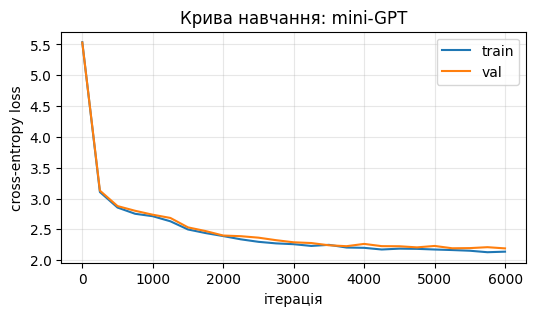

In [51]:
plt.figure(figsize=(6, 3))
plt.plot(checkpoint_iters, train_losses, label="train")
plt.plot(checkpoint_iters, val_losses, label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

##### Генерація на різних стадіях тренування

In [52]:
def generate_text(state_dict_path: str, prompt: str, max_new_tokens: int = 20,
                   temperature: float = 1.2, top_k: int = 40) -> str:
    model.load_state_dict(torch.load(state_dict_path, map_location=device))
    prompt_ids = torch.tensor([encode(prompt)], dtype=torch.long).to(device)
    out_ids = model.generate(prompt_ids, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(out_ids[0].tolist())


PROMPT = "Dm7 C Am7 G7 Fmaj7"

print("=== Ранній чекпоінт (iter", checkpoint_iters[0], ") ===")
print(generate_text(FIRST_CKPT_PATH, PROMPT))
print(f"\n=== Найкращий чекпоінт (iter {best_iter}, val_loss={best_val_loss:.3f}) ===")
print(generate_text(BEST_CKPT_PATH, PROMPT))

=== Ранній чекпоінт (iter 0 ) ===
Dm7 C Am7 G7 Fmaj7 E7/G# Fm7 Eb/G Eb</E#<e Ebaug E C#/G# D <e Abaug D/E B7/D# Eb C7 Cdim G6 F#m7

=== Найкращий чекпоінт (iter 5999, val_loss=2.191) ===
Dm7 C Am7 G7 Fmaj7 G6 F6 Fmaj7 Dm7 Am G6 Dm6 Fmaj7 Dm7b5 Am G6 Am F6 Em G7 C G D7 G6 D


#### 3.2.3. Друга модель

##### Гіперпараметри

In [53]:
CONTEXT_LEN = 128       # скільки попередніх токенів бачить модель
EMBED_DIM = 256         # розмірність embedding
N_HEADS = 8             # кількість attention-голів
N_LAYERS = 4            # кількість блоків трансформера
DROPOUT = 0.1           # рівень dropout для регуляризації
BATCH_SIZE = 64         # розмір батчу
LEARNING_RATE = 5e-4    # швидкість навчання
MAX_ITERS = 6000        # кількість ітерацій навчання
EVAL_INTERVAL = 250     # інтервал (в ітераціях) для оцінки моделі на валідаційній вибірці
EVAL_ITERS = 50         # кількість ітерацій для оцінки на валідаційній вибірці

assert EMBED_DIM % N_HEADS == 0, "EMBED_DIM має ділитися на N_HEADS"
HEAD_DIM = EMBED_DIM // N_HEADS

##### Батчі

In [54]:
def get_batch(split: str):
    source = train_data if split == "train" else val_data
    ix = torch.randint(len(source) - CONTEXT_LEN - 1, (BATCH_SIZE,))
    x = torch.stack([source[i:i + CONTEXT_LEN] for i in ix])
    y = torch.stack([source[i + 1:i + CONTEXT_LEN + 1] for i in ix])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")

assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN), "Неправильна форма батчів"
assert torch.equal(xb[:, 1:], yb[:, :-1]), "Порушено зсув"

print("Форма батчу x:", xb.shape, " y:", yb.shape)

Форма батчу x: torch.Size([64, 128])  y: torch.Size([64, 128])


##### Ініціалізація

In [55]:
model = MiniGPT(
    vocab_size=len(itos),
    embed_dim=EMBED_DIM,
    n_heads=N_HEADS,
    n_layers=N_LAYERS,
    context_len=CONTEXT_LEN,
    dropout=DROPOUT,
).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"Кількість параметрів: {n_params:,}")

Кількість параметрів: 3,320,063


##### Тренування

In [56]:
from torch.utils.tensorboard import SummaryWriter

@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ("train", "val"):
        losses = torch.zeros(EVAL_ITERS)
        for i in range(EVAL_ITERS):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[i] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "chords_ctx128_d256_L4"))

FIRST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "chords_ctx128_d256_L4_first.pt")
BEST_CKPT_PATH = os.path.join(ARTIFACT_DIR, "chords_ctx128_d256_L4_best.pt")

train_losses, val_losses, checkpoint_iters = [], [], []
best_val_loss = float("inf")
best_iter = None
start_time = time.time()

for it in range(MAX_ITERS):
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if it % EVAL_INTERVAL == 0 or it == MAX_ITERS - 1:
        losses = estimate_loss()
        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        checkpoint_iters.append(it)
        writer.add_scalar("Loss/train", losses["train"], it)
        writer.add_scalar("Loss/val", losses["val"], it)

        elapsed_min = (time.time() - start_time) / 60
        print(f"iter {it:5d}  train_loss={losses['train']:.3f}  "
              f"val_loss={losses['val']:.3f}  ({elapsed_min:.1f} хв)")

        if it == 0:
            torch.save(model.state_dict(), FIRST_CKPT_PATH)

        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            best_iter = it
            torch.save(model.state_dict(), BEST_CKPT_PATH)

writer.close()
print(f"\nТренування завершено за {(time.time() - start_time) / 60:.1f} хв")
print(f"Найкращий чекпоінт: iter {best_iter}  (val_loss={best_val_loss:.3f})")

iter     0  train_loss=5.249  val_loss=5.264  (0.1 хв)
iter   250  train_loss=2.759  val_loss=2.809  (0.6 хв)
iter   500  train_loss=2.615  val_loss=2.648  (1.2 хв)
iter   750  train_loss=2.309  val_loss=2.360  (1.7 хв)
iter  1000  train_loss=2.198  val_loss=2.255  (2.3 хв)
iter  1250  train_loss=2.126  val_loss=2.177  (2.8 хв)
iter  1500  train_loss=2.100  val_loss=2.146  (3.3 хв)
iter  1750  train_loss=2.049  val_loss=2.125  (3.9 хв)
iter  2000  train_loss=2.014  val_loss=2.082  (4.4 хв)
iter  2250  train_loss=2.011  val_loss=2.065  (5.0 хв)
iter  2500  train_loss=1.986  val_loss=2.064  (5.5 хв)
iter  2750  train_loss=1.974  val_loss=2.067  (6.1 хв)
iter  3000  train_loss=1.940  val_loss=2.055  (6.6 хв)
iter  3250  train_loss=1.909  val_loss=2.026  (7.2 хв)
iter  3500  train_loss=1.911  val_loss=2.042  (7.7 хв)
iter  3750  train_loss=1.898  val_loss=2.013  (8.3 хв)
iter  4000  train_loss=1.873  val_loss=1.999  (8.8 хв)
iter  4250  train_loss=1.866  val_loss=1.998  (9.4 хв)
iter  4500

##### Крива навчання

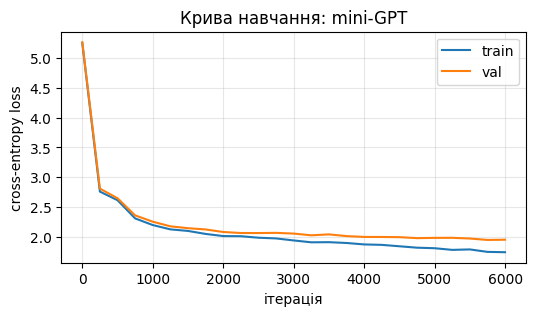

In [57]:
plt.figure(figsize=(6, 3))
plt.plot(checkpoint_iters, train_losses, label="train")
plt.plot(checkpoint_iters, val_losses, label="val")
plt.xlabel("ітерація"); plt.ylabel("cross-entropy loss"); plt.title("Крива навчання: mini-GPT")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

##### Генерація на різних стадіях тренування

In [58]:
def generate_text(state_dict_path: str, prompt: str, max_new_tokens: int = 20,
                   temperature: float = 1.2, top_k: int = 40) -> str:
    model.load_state_dict(torch.load(state_dict_path, map_location=device))
    prompt_ids = torch.tensor([encode(prompt)], dtype=torch.long).to(device)
    out_ids = model.generate(prompt_ids, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(out_ids[0].tolist())


PROMPT = "Dm7 C Am7 G7 Fmaj7"

print("=== Ранній чекпоінт (iter", checkpoint_iters[0], ") ===")
print(generate_text(FIRST_CKPT_PATH, PROMPT))
print(f"\n=== Найкращий чекпоінт (iter {best_iter}, val_loss={best_val_loss:.3f}) ===")
print(generate_text(BEST_CKPT_PATH, PROMPT))

=== Ранній чекпоінт (iter 0 ) ===
Dm7 C Am7 G7 Fmaj7 E/F# C Abm <e A D G Am A C#aug Bb/Ab D/F# <e F#/A# A/E Ebm7b5 F#m B/C# Bm7b5/A

=== Найкращий чекпоінт (iter 5750, val_loss=1.949) ===
Dm7 C Am7 G7 Fmaj7 Dm Bb Am Gm7 C Dm Gm7 C7 F Dm F Bbmaj7 C7 F Dm C Am Dm Fmaj7 Dm


### 3.3. Висновки

Обидва варіанти використовують один токенізатор (`VOCAB_LEN = 255`, 1 токен = 1 акорд), однакові `BATCH_SIZE = 64` і `MAX_ITERS = 6000`. Генерація — на best-чекпоінті з тим самим `PROMPT = "Dm7 C Am7 G7 Fmaj7"`, `temperature=1.2`, `top_k=40`.

| | v1 `chords_ctx64_d128_L8` | v2 `chords_ctx128_d256_L4` |
|---|---|---|
| `CONTEXT_LEN` / `EMBED_DIM` / `N_HEADS` / `N_LAYERS` / `LR` | 64 / 128 / 4 / 8 / 3e-4 | 128 / 256 / 8 / 4 / 5e-4 |
| Параметрів | 1.66 млн | 3.32 млн |
| Best `val_loss` (iter) | 2.204 (5999) | **1.942** (5999) |
| Перплексія `exp(val_loss)` | ≈ 9.1 | ≈ 7.0 |
| `train_loss` наприкінці / розрив `val − train` | 2.138 / 0.066 | 1.736 / 0.206 |
| Токенів пройшло через модель за тренування | 24.6 млн (≈ 11 проходів по train) | 49.2 млн (≈ 22 проходи) |
| Час тренування | 6.1 хв | 11.8 хв |

**Який варіант кращий за `val_loss`?** Варіант v2: 1.942 проти 2.204, тобто на 0.26 нат - ≈12% нижче; у перплексії це «вагання» між ≈ 7 акордами замість ≈ 9. Обидві моделі набагато кращі за базові рівні з 3.1.3, тож обидві справді навчилися використовувати контекст. Різниця між ними в кілька разів більша за шум оцінки, тож це не випадковість. В обох best-чекпоінт збігається з останнім: перенавчання ще не почалося. Втім, v2 ближча до насичення: від iter 5000 її `val_loss` тримається на 1.94–1.98, а `train_loss` далі падає, і розрив train/val утричі більший, ніж у v1.

**Чи помітно це в згенерованому тексті?** Так, хоча це спостереження на одному семплі при високій температурі, тож це ілюстрація, а не доказ. v1 дає правдоподібні перші п'ять акордів `Em7 Am D C/D D`, а далі розсипається у далекі тональності та екзотичні акорди `Bbm Bb7 F#maj7 Ab Bbm C#/G# … Abm7`. v2 лишається в тональності промпту `Dm C F6 C Bb Fmaj7`, будує типовий поп-цикл `C Bb F` і тричі його повторює, перш ніж перейти в Bm. Мінус v2 — схильність до петель, що характерно для корпусу з циклічними прогресіями. Щоб перевірити це надійніше, треба згенерувати десятки семплів і порахувати, наприклад, частку акордів «у тональності».

**Що дало найбільший ефект?** Варіанти відрізняються одразу кількома параметрами, тому строго розділити їхній внесок неможливо.

- **Словник** у цьому експерименті не варіювався (255 токенів в обох), тому про його вплив висновків немає. Через це `CONTEXT_LEN` дорівнює кількості акордів у вікні.
- **Довжина контексту** — найімовірніший головний чинник. Медіанна композиція має 79 акордів: вікно 64 не вміщує навіть типову пісню, а 128 охоплює більшість. Прогресії циклічні, тож довший контекст дозволяє attention дивитися на вже зіграні такти, визначати тональність і продовжувати цикл. На користь цього: v2 нижча за v1 на кожному чекпоінті, а в тексті саме v2 тримає тональність. Застереження: вікно 128 дає вдвічі більше токенів за ітерацію, тож частина виграшу — це просто вдвічі більше даних за той самий `MAX_ITERS`.
- **Глибина** не стала вузьким місцем: v2 має вдвічі менше шарів і все одно краща. Вузька й глибока v1 довго стояла на плато `val_loss` ≈ 2.7 на iter 1000–1250 і лише потім різко пішла вниз; v2 пройшла схожий злам набагато раніше. Імовірно, на це вплинули ширші шари `EMBED_DIM` і вищий `LEARNING_RATE`.
- **Ціна:** v2 удвічі більша і тренується в 1.9 раза довше, зате вже на iter 1250 мала `val_loss = 2.193` — нижче за фінальний результат v1. Тобто до якості v1 вона дійшла приблизно в 2.4 раза швидше.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

In [59]:
import gc, torch

def ram_gb():
    try:
        import psutil
        return psutil.Process(os.getpid()).memory_info().rss / 1e9
    except ImportError:
        return float("nan")



ram_before = ram_gb()

HEAVY_NAMES = [
    # датасет і тексти
    "chords_dataset", "splits", "train_raw", "test_raw", "train_sequences", "test_sequences",
    "train_texts", "test_texts", "train_texts_with_eos", "train_df", "test_df", "corpus_text",
    "all_train_chords", "chord_frequencies", "test_chords_flat", "comparison_text", "unseen_in_train",
    "ranked", "most_common_chords", "rarest_chords", "summary_rows", "summary_df", "word_rows",
    "song_lengths", "n_events", "best",
    # токенізатори
    "base_tokenizer", "qwen_chord_tokenizer", "bpe_tokenizer", "bpe_trainer", "wordpiece_tokenizer",
    "wordpiece_trainer", "unigram_tokenizer", "unigram_trainer", "tokenizers_to_compare",
    "chosen_tokenizer", "loaded_tokenizer", "itos", "stoi",
    # закодований корпус, модель і тренування
    "train_data", "val_data", "train_np", "val_np", "p_train", "p_val", "xb", "yb",
    "model", "optimizer", "writer", "train_losses", "val_losses", "checkpoint_iters",
]
freed = [name for name in HEAVY_NAMES if name in globals()]
for name in freed:
    del globals()[name]

for name, obj in list(globals().items()):
    if not name.startswith("_") and isinstance(obj, (torch.Tensor, nn.Module, torch.optim.Optimizer)):
        del globals()[name]
        freed.append(name)

plt.close("all")
try:
    get_ipython().run_line_magic("reset", "-f out")
except Exception:
    pass

gc.collect()
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")

print(f"\nВивільнено змінних: {len(freed)}")
print(f"RAM процесу: {ram_before:.2f} GB → {ram_gb():.2f} GB")

Flushing output cache (1 entries)
GPU: зайнято 0.02 GB

Вивільнено змінних: 55
RAM процесу: 2.75 GB → 2.59 GB


### 4.0. Запустіть приклади виконання різних NLP задач

In [83]:
!pip install "transformers[sentencepiece]==5.18.0"

In [61]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1739: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1771: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [62]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [63]:
# Text generation
from transformers import pipeline

generator = pipeline("text-generation")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

... (15 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'max_length'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to do this. This course will be a free course. We will teach you how to do this. This course will be a free course. We will teach you how to do this. This course will be a free course. We will teach you how to do this.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'}, {'generated_text': 'In this course, we will teach you how to make a living with a book that you don\'t have to buy or share. We will also teach you how to make a living with a book that you don\'t have to buy or share.\n\n\n\n\n\nAbout the book\nWhat is the book?\nThe book is a hand-written book by a self-describe

In [64]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask")
unmasker("This course will teach you all about <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [65]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [66]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

#### Виконання 4.1

Дефолтні моделі `pipeline()` англомовні, тому для української явно задаю багатомовні. Кожен виклик іде через допоміжну `make_pipe`: вона пробує моделі зі списку по черзі, тож недоступний id не зупинить «Run All».

| Задача | Модель (перший кандидат) | Чому |
|---|---|---|
| sentiment-analysis | `lxyuan/distilbert-base-multilingual-cased-sentiments-student` | багатомовний DistilBERT, 3 класи (positive / neutral / negative) |
| zero-shot-classification | `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` | багатомовна NLI-модель: підписи класів і шаблон гіпотези можна давати українською |
| text-generation | `Qwen/Qwen3-1.7B-Base` | багатомовна базова LLM (у демо — Qwen3-4B), продовжує текст без chat-шаблону |
| fill-mask | `FacebookAI/xlm-roberta-base` | XLM-R вчили на CC-100 (100 мов, серед них українська) |
| NER | `Davlan/xlm-roberta-base-ner-hrl` | XLM-R, дотренований на NER для 10 мов; української серед них немає, тож це міжмовне перенесення |
| table-question-answering | `google/tapas-base-finetuned-wtq` | дефолтна TAPAS англомовна; для порівняння додано Qwen, який бачить таблицю як текст |

In [67]:
import gc
import torch
from transformers import pipeline, set_seed

PIPE_DEVICE = 0 if torch.cuda.is_available() else -1
set_seed(42)


def make_pipe(task, candidates, **kwargs):
    last_error = None
    for model_id in candidates:
        try:
            pipe = pipeline(task, model=model_id, device=PIPE_DEVICE, **kwargs)
            print(f"[{task}] модель: {model_id}")
            return pipe
        except Exception as e:
            print(f"[{task}] {model_id} не завантажилась: {type(e).__name__}: {str(e)[:120]}")
            last_error = e
    raise last_error


def cleanup():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

##### 4.1.1. Sentiment analysis

In [68]:
classifier = make_pipe("sentiment-analysis", [
    "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "cardiffnlp/twitter-xlm-roberta-base-sentiment",
])

uk_sentences = [
    "Я так довго чекав на цей курс, і він навіть кращий, ніж я сподівався!",
    "Потяг знову запізнився на дві години, це просто жахливо.",
    "Сьогодні вівторок, засідання відбудеться о третій годині.",
]

for text, res in zip(uk_sentences, classifier(uk_sentences)):
    print(f"{res['label']:>9} ({res['score']:.3f})  <-  {text}")

del classifier
cleanup()

config.json:   0%|          | 0.00/759 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1739: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1771: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/373 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

[sentiment-analysis] модель: lxyuan/distilbert-base-multilingual-cased-sentiments-student
 negative (0.456)  <-  Я так довго чекав на цей курс, і він навіть кращий, ніж я сподівався!
 negative (0.823)  <-  Потяг знову запізнився на дві години, це просто жахливо.
 positive (0.406)  <-  Сьогодні вівторок, засідання відбудеться о третій годині.


##### 4.1.2. Zero-shot classification

In [69]:
zero_shot = make_pipe("zero-shot-classification", [
    "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
    "joeddav/xlm-roberta-large-xnli",
])

zs_texts = [
    "Наша футбольна команда вчора виграла фінал і здобула кубок.",
    "Національний банк підвищив облікову ставку, через що подорожчали кредити.",
    "Дослідники виявили нову екзопланету, на якій може бути вода.",
    "У театрі відкрився новий сезон прем'єрою за п'єсою Лесі Українки.",
]
zs_labels = ["спорт", "економіку", "науку", "політику", "культуру"]

zs_results = zero_shot(zs_texts, candidate_labels=zs_labels, hypothesis_template="Це речення про {}.")
for r in zs_results:
    top3 = ", ".join(f"{label} ({score:.2f})" for label, score in zip(r["labels"][:3], r["scores"][:3]))
    print(r["sequence"])
    print("   ->", top3)

del zero_shot
cleanup()

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

... (2 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

[zero-shot-classification] модель: MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7
Наша футбольна команда вчора виграла фінал і здобула кубок.
   -> спорт (0.95), культуру (0.02), науку (0.02)
Національний банк підвищив облікову ставку, через що подорожчали кредити.
   -> політику (0.46), економіку (0.35), науку (0.12)
Дослідники виявили нову екзопланету, на якій може бути вода.
   -> науку (0.94), політику (0.03), економіку (0.01)
У театрі відкрився новий сезон прем'єрою за п'єсою Лесі Українки.
   -> культуру (0.92), політику (0.03), науку (0.02)


##### 4.1.3. Text generation

In [70]:
generator = make_pipe("text-generation", [
    "Qwen/Qwen3-1.7B-Base",
    "Qwen/Qwen2.5-1.5B",
    "Qwen/Qwen2.5-0.5B",
])

gen_prompt = "Одного разу взимку в Карпатах, коли випав перший сніг,"
gen_outputs = generator(
    gen_prompt,
    max_new_tokens=60,
    do_sample=True,
    temperature=0.8,
    top_p=0.9,
    num_return_sequences=2,
)
for i, out in enumerate(gen_outputs, 1):
    print(f"--- варіант {i} ---")
    print(out["generated_text"], "\n")

config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.68k [00:00<?, ?B/s]

... (3 outputs left out)

[transformers] The following generation flags are not valid and may be ignored: ['temperature']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
[transformers] Passing `generation_config` together with generation-related arguments=({'num_return_sequences', 'top_p', 'temperature', 'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[text-generation] модель: Qwen/Qwen3-1.7B-Base


[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


--- варіант 1 ---
Одного разу взимку в Карпатах, коли випав перший сніг, як-от із світлої нічі похмуріє, і висить крихітна туманність. Знімаючись над рівним більшістю Карпат 

--- варіант 2 ---
Одного разу взимку в Карпатах, коли випав перший сніг, що сталося із вітрилами?

Зустрічна вітерна стічка. Вітрилами називаються ближні льодовики, які ділять ліжок на 



##### 4.1.4. Fill-mask

In [71]:
unmasker = make_pipe("fill-mask", [
    "FacebookAI/xlm-roberta-base",
    "google-bert/bert-base-multilingual-cased",
])

mask = unmasker.tokenizer.mask_token
mask_sentences = [
    f"Київ — столиця {mask}.",
    f"Я люблю пити вранці гарячу {mask} з молоком.",
    f"Цей курс навчить вас усього про {mask} моделі.",
]

for sentence in mask_sentences:
    print(sentence)
    for r in unmasker(sentence, top_k=5):
        print(f"   {r['token_str'].strip():<15} {r['score']:.3f}")

del unmasker
cleanup()

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

[fill-mask] модель: FacebookAI/xlm-roberta-base
Київ — столиця <mask>.
   України         0.441
   .               0.089
   Україна         0.053
   Європи          0.046
   ,               0.046
Я люблю пити вранці гарячу <mask> з молоком.
   воду            0.918
   води            0.013
   ,               0.007
   суміш           0.006
   чай             0.004
Цей курс навчить вас усього про <mask> моделі.
   створення       0.113
   ці              0.087
   різні           0.044
   цієї            0.035
   розвиток        0.035


##### 4.1.5. Named entity recognition

In [72]:
ner = make_pipe("ner", [
    "Davlan/xlm-roberta-base-ner-hrl",
    "Davlan/bert-base-multilingual-cased-ner-hrl",
], aggregation_strategy="simple")

ner_texts = [
    "Тарас Шевченко народився в селі Моринці, а помер у Санкт-Петербурзі.",
    "Олена працює в компанії «Нова пошта» і щоліта відпочиває в Одесі.",
    "Лекцію про трансформери в Києві прочитав Андрій, який працює в Google.",
]

for text in ner_texts:
    print(text)
    for e in ner(text):
        print(f"   {e['entity_group']:<5} {e['word']!r:<26} {e['score']:.2f}")

del ner
cleanup()

config.json:   0%|          | 0.00/980 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/211 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

[ner] модель: Davlan/xlm-roberta-base-ner-hrl
Тарас Шевченко народився в селі Моринці, а помер у Санкт-Петербурзі.
   PER   'Тарас Шевченко'           1.00
   LOC   'Моринці'                  0.93
   LOC   'Санкт-Петербурзі'         1.00
Олена працює в компанії «Нова пошта» і щоліта відпочиває в Одесі.
   PER   'Олена'                    0.95
   ORG   '«Нова пошта»'             0.99
   LOC   'Одесі'                    0.84
Лекцію про трансформери в Києві прочитав Андрій, який працює в Google.
   LOC   'Києві'                    1.00
   PER   'Андрій'                   1.00
   ORG   'Google'                   1.00


##### 4.1.6. Table question answering

TAPAS навчали на англомовних таблицях з англійським словником, тож з українською вона може помилятися. Це обмеження моделі, а не коду. Тому ті самі запитання ставлю ще й Qwen із 4.1.3, якому таблиця подається як звичайний текст.

In [73]:
uk_table = {
    "Предмет": ["Алгоритми", "Бази даних", "Машинне навчання"],
    "Студентів": ["120", "85", "240"],
    "Кредитів ECTS": ["5", "4", "6"],
    "Мова програмування": ["C++", "SQL", "Python"],
}
uk_questions = [
    "Скільки студентів на предметі Машинне навчання?",
    "Яка мова програмування на предметі Бази даних?",
    "Скільки студентів на всіх предметах разом?",
]

tqa = make_pipe("table-question-answering", ["google/tapas-base-finetuned-wtq"])
print("=== TAPAS ===")
for q in uk_questions:
    ans = tqa(table=uk_table, query=q)
    print(f"{q}\n   -> {ans['answer']}   (клітинки: {ans.get('cells')})")


def table_to_text(table):
    rows = [" | ".join(table)]
    rows += [" | ".join(row) for row in zip(*table.values())]
    return "\n".join(rows)


print("\n=== Qwen (таблиця як текст) ===")
for q in uk_questions:
    prompt = f"Таблиця:\n{table_to_text(uk_table)}\n\nПитання: {q}\nКоротка відповідь:"
    out = generator(prompt, max_new_tokens=15, do_sample=False, return_full_text=False)[0]["generated_text"]
    first_line = out.strip().splitlines()[0] if out.strip() else ""
    print(f"{q}\n   -> {first_line}")

for name in ("tqa", "generator"):
    globals().pop(name, None)
cleanup()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[table-question-answering] модель: google/tapas-base-finetuned-wtq
=== TAPAS ===
Скільки студентів на предметі Машинне навчання?
   -> Машинне навчання   (клітинки: ['Машинне навчання'])
Яка мова програмування на предметі Бази даних?
   -> Машинне навчання   (клітинки: ['Машинне навчання'])
Скільки студентів на всіх предметах разом?
   -> Машинне навчання   (клітинки: ['Машинне навчання'])

=== Qwen (таблиця як текст) ===


[transformers] Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Скільки студентів на предметі Машинне навчання?
   -> 240 студентів.


[transformers] Both `max_new_tokens` (=15) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Яка мова програмування на предметі Бази даних?
   -> SQL
Скільки студентів на всіх предметах разом?
   -> 120 + 85 + 240 =


---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

#### Виконання 5.1. Задача, дані, метрика

**Задача:** sentiment-analysis. **Метрики:** Accuracy і F1 (macro), обидві через `evaluate`.

**Дані:** 20 власних речень. Більшість прості, але є й «пастки»: заперечення і сарказм. Колонка `тип` потрібна, щоб потім побачити, на чому моделі помиляються.

**Три кандидати**:
- `cardiffnlp/twitter-xlm-roberta-base-sentiment`: XLM-R base, класи negative / neutral / positive;
- `lxyuan/distilbert-base-multilingual-cased-sentiments-student`: стиснений DistilBERT, ті самі 3 класи;
- `nlptown/bert-base-multilingual-uncased-sentiment`: mBERT, оцінка в «зірках» 1–5.

Мітки моделей різні, тому функція `polarity` зводить їх до negative / neutral / positive. Наша розмітка бінарна, тож рішення приймається так: `P(pos) / (P(pos) + P(neg)) ≥ τ`, а нейтральний клас просто ігнорується. Базове значення `τ = 0.5`.

In [74]:
!pip install -q evaluate scikit-learn

In [75]:
import re
import time
import gc

import numpy as np
import pandas as pd
import torch
import evaluate
from transformers import pipeline

PIPE_DEVICE = 0 if torch.cuda.is_available() else -1
print("Пристрій для інференсу:", "GPU" if PIPE_DEVICE == 0 else "CPU")


def cleanup():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

eval_data = [
    ("Дуже смачна піца, обслуговування швидке, обов'язково повернемося ще!", 1, "просте"),
    ("Лекція була неймовірно цікавою, я нарешті зрозумів, як працюють трансформери.", 1, "просте"),
    ("Кур'єр приїхав раніше, ніж обіцяли, і їжа була ще гарячою.", 1, "просте"),
    ("Поїздка в Карпати перевершила всі очікування — краєвиди просто неймовірні.", 1, "просте"),
    ("Новий телефон працює швидко, а камера робить чудові знімки навіть уночі.", 1, "просте"),
    ("Щиро дякую за допомогу, ви мене дуже виручили!", 1, "просте"),
    ("Книга захоплює з першої сторінки, не міг відірватися до ранку.", 1, "просте"),
    ("Готель чистий, персонал привітний, а сніданок різноманітний.", 1, "просте"),
    ("Не очікував, що фільм буде таким гарним, — не пошкодував ні про хвилину.", 1, "заперечення"),
    ("Ну нарешті літо! Сонце світить, настрій чудовий, усім усміхаюся.", 1, "просте"),
    ("Їжа була холодна, офіціант грубив, більше сюди ні ногою.", 0, "просте"),
    ("Додаток постійно вилітає, а підтримка не відповідає вже тиждень.", 0, "просте"),
    ("Потяг запізнився на три години, а у вагоні не працювало опалення.", 0, "просте"),
    ("Серіал — суцільне розчарування: сюжет нудний і передбачуваний.", 0, "просте"),
    ("Замовлення привезли не те, а гроші повертати відмовляються.", 0, "просте"),
    ("Погода жахлива: дощ, вітер, і настрій відповідний.", 0, "просте"),
    ("Чудово, інтернет зник якраз за п'ять хвилин до дедлайну.", 0, "сарказм"),
    ("Не можу сказати, що поїздка мені сподобалась: забагато черг і галасу.", 0, "заперечення"),
    ("Ремонт обійшовся вдвічі дорожче, ніж обіцяли, і зроблений абияк.", 0, "просте"),
    ("Я втомився від цих нескінченних відключень світла, жити неможливо.", 0, "просте"),
]
eval_df = pd.DataFrame(eval_data, columns=["text", "label", "тип"])
texts = eval_df["text"].tolist()
y_true = eval_df["label"].tolist()
print(eval_df["label"].value_counts().rename({1: "позитивних", 0: "негативних"}).to_dict(),
      "| типи:", eval_df["тип"].value_counts().to_dict())

accuracy_metric = evaluate.load("accuracy")
f1_metric = evaluate.load("f1")


def polarity(label):
    l = label.strip().lower()
    stars = re.match(r"(\d)\s*star", l)
    if stars:
        n = int(stars.group(1))
        return "negative" if n <= 2 else "neutral" if n == 3 else "positive"
    if l in ("negative", "neg", "label_0"):
        return "negative"
    if l in ("neutral", "neu", "label_1"):
        return "neutral"
    if l in ("positive", "pos", "label_2"):
        return "positive"
    raise ValueError(f"Невідома мітка: {label!r}")


def get_probs(pipe, input_texts, batch_size=8):
    raw = pipe(list(input_texts), top_k=None, batch_size=batch_size, truncation=True, max_length=128)
    rows = []
    for item in raw:
        item = item if isinstance(item, list) else [item]
        p = {"negative": 0.0, "neutral": 0.0, "positive": 0.0}
        for d in item:
            p[polarity(d["label"])] += d["score"]
        rows.append(p)
    return pd.DataFrame(rows)


def predict(probs, threshold=0.5):
    pos_share = probs["positive"] / (probs["positive"] + probs["negative"])
    return (pos_share >= threshold).astype(int).to_numpy()


def score(y_true, y_pred):
    y_pred = [int(v) for v in y_pred]
    acc = accuracy_metric.compute(predictions=y_pred, references=y_true)["accuracy"]
    f1 = f1_metric.compute(predictions=y_pred, references=y_true, average="macro")["f1"]
    return acc, f1

Пристрій для інференсу: GPU
{'позитивних': 10, 'негативних': 10} | типи: {'просте': 17, 'заперечення': 2, 'сарказм': 1}


#### Виконання 5.2. Порівняння моделей

Для кожної моделі міряю: Accuracy, F1 (macro), кількість параметрів і швидкість - середній час на речення після прогріву; 3 прогони по всіх 20 реченнях, `batch_size=8`.

In [76]:
SENTIMENT_MODELS = {
    "XLM-R base (cardiffnlp)": "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    "DistilmBERT (lxyuan)": "lxyuan/distilbert-base-multilingual-cased-sentiments-student",
    "mBERT stars (nlptown)": "nlptown/bert-base-multilingual-uncased-sentiment",
}

rows, probs_store = [], {}
for name, model_id in SENTIMENT_MODELS.items():
    try:
        pipe = pipeline("sentiment-analysis", model=model_id, device=PIPE_DEVICE)
    except Exception as e:
        print(f"{name}: не вдалося завантажити ({type(e).__name__}: {str(e)[:100]}) — пропускаю")
        continue

    n_params = sum(p.numel() for p in pipe.model.parameters())
    get_probs(pipe, texts[:4])

    times = []
    for _ in range(3):
        t0 = time.perf_counter()
        probs = get_probs(pipe, texts)
        times.append(time.perf_counter() - t0)

    acc, f1 = score(y_true, predict(probs))
    probs_store[name] = probs
    rows.append({
        "Модель": name,
        "Параметрів, млн": round(n_params / 1e6, 1),
        "Accuracy": round(acc, 3),
        "F1 (macro)": round(f1, 3),
        "мс на речення": round(float(np.mean(times)) / len(texts) * 1000, 1),
    })
    del pipe
    cleanup()

assert len(rows) >= 2, "Для порівняння потрібно щонайменше 2 моделі"
comparison_df = (pd.DataFrame(rows)
                 .sort_values(["F1 (macro)", "Accuracy", "мс на речення"], ascending=[False, False, True])
                 .reset_index(drop=True))
display(comparison_df)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1739: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1771: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

... (9 outputs left out)

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

,Модель,"Параметрів, млн",Accuracy,F1 (macro),мс на речення
0,XLM-R base (cardiffnlp),278.0,0.9,0.899,8.5
1,mBERT stars (nlptown),167.4,0.7,0.700,6.6
2,DistilmBERT (lxyuan),135.3,0.5,0.495,2.5


In [77]:
labels_arr = eval_df["label"].to_numpy()
correct_df = pd.DataFrame({name: predict(p) == labels_arr for name, p in probs_store.items()})
print("Частка правильних відповідей за типом речення:")
display(correct_df.groupby(eval_df["тип"]).mean().round(2))

for name, p in probs_store.items():
    wrong = eval_df[predict(p) != labels_arr]
    print(f"\n{name}: помилок {len(wrong)} з {len(eval_df)}")
    for _, r in wrong.iterrows():
        gold = "positive" if r["label"] == 1 else "negative"
        print(f"   [{r['тип']}] мало бути {gold}: {r['text']}")

Частка правильних відповідей за типом речення:


,XLM-R base (cardiffnlp),DistilmBERT (lxyuan),mBERT stars (nlptown)
тип,,,
заперечення,0.50,0.50,0.50
просте,0.94,0.47,0.71
сарказм,1.00,1.00,1.00



XLM-R base (cardiffnlp): помилок 2 з 20
   [заперечення] мало бути negative: Не можу сказати, що поїздка мені сподобалась: забагато черг і галасу.
   [просте] мало бути negative: Ремонт обійшовся вдвічі дорожче, ніж обіцяли, і зроблений абияк.

DistilmBERT (lxyuan): помилок 10 з 20
   [просте] мало бути positive: Лекція була неймовірно цікавою, я нарешті зрозумів, як працюють трансформери.
   [просте] мало бути positive: Кур'єр приїхав раніше, ніж обіцяли, і їжа була ще гарячою.
   [просте] мало бути positive: Поїздка в Карпати перевершила всі очікування — краєвиди просто неймовірні.
   [просте] мало бути positive: Книга захоплює з першої сторінки, не міг відірватися до ранку.
   [заперечення] мало бути positive: Не очікував, що фільм буде таким гарним, — не пошкодував ні про хвилину.
   [просте] мало бути positive: Ну нарешті літо! Сонце світить, настрій чудовий, усім усміхаюся.
   [просте] мало бути negative: Додаток постійно вилітає, а підтримка не відповідає вже тиждень.
   [прост

#### Виконання 5.3. Налаштування найкращої моделі

Беру модель із найвищим F1 з 5.2 і змінюю **по одному параметру за раз** відносно базового запуску:

1. `τ = 0.3`: поріг нижчий, тож модель частіше каже «позитивне»;
2. `τ = 0.7`: поріг вищий, тож модель частіше каже «негативне»;
3. текст у нижній регістр;
4. текст без розділових знаків.

Зміни 1–2 не потребують нового інференсу, зміни 3–4 міняють вхід, тож модель запускається знову. Окремо для найкращої моделі рахую Accuracy на сітці `τ`.

In [78]:
best_name = comparison_df.iloc[0]["Модель"]
best_id = SENTIMENT_MODELS[best_name]
print("Найкраща модель за F1:", best_name, "|", best_id)

best_pipe = pipeline("sentiment-analysis", model=best_id, device=PIPE_DEVICE)


def strip_punct(t):
    return re.sub(r"[^\w\s']", "", t)


base_probs = probs_store[best_name]
variants = {
    "baseline (τ=0.5, сирий текст)": (base_probs, 0.5),
    "τ = 0.3": (base_probs, 0.3),
    "τ = 0.7": (base_probs, 0.7),
    "нижній регістр": (get_probs(best_pipe, [t.lower() for t in texts]), 0.5),
    "без розділових знаків": (get_probs(best_pipe, [strip_punct(t) for t in texts]), 0.5),
}

exp_rows = []
for setting, (probs, tau) in variants.items():
    acc, f1 = score(y_true, predict(probs, tau))
    exp_rows.append({"Модель": best_name, "Налаштування": setting,
                     "Accuracy": round(acc, 3), "F1 (macro)": round(f1, 3)})
exp_df = pd.DataFrame(exp_rows)
exp_df["Δ Accuracy"] = (exp_df["Accuracy"] - exp_df.loc[0, "Accuracy"]).round(3)

del best_pipe
cleanup()

others = comparison_df[comparison_df["Модель"] != best_name][["Модель", "Accuracy", "F1 (macro)"]].copy()
others["Налаштування"] = "baseline (τ=0.5, сирий текст)"
others["Δ Accuracy"] = 0.0
all_results_df = pd.concat([exp_df, others], ignore_index=True)[
    ["Модель", "Налаштування", "Accuracy", "F1 (macro)", "Δ Accuracy"]]
display(all_results_df)

tau_grid = [round(t, 1) for t in np.arange(0.1, 0.95, 0.1)]
tau_df = pd.DataFrame({
    "τ": tau_grid,
    "Accuracy": [round(score(y_true, predict(base_probs, t))[0], 3) for t in tau_grid],
})
print("\nAccuracy найкращої моделі залежно від τ:")
display(tau_df.T)

Найкраща модель за F1: XLM-R base (cardiffnlp) | cardiffnlp/twitter-xlm-roberta-base-sentiment


/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1739: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1771: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,Модель,Налаштування,Accuracy,F1 (macro),Δ Accuracy
0,XLM-R base (cardiffnlp),"baseline (τ=0.5, сирий текст)",0.90,0.899,0.00
1,XLM-R base (cardiffnlp),τ = 0.3,0.85,0.847,-0.05
2,XLM-R base (cardiffnlp),τ = 0.7,0.90,0.900,0.00
3,XLM-R base (cardiffnlp),нижній регістр,0.85,0.847,-0.05
4,XLM-R base (cardiffnlp),без розділових знаків,0.85,0.850,-0.05
5,mBERT stars (nlptown),"baseline (τ=0.5, сирий текст)",0.70,0.700,0.00
6,DistilmBERT (lxyuan),"baseline (τ=0.5, сирий текст)",0.50,0.495,0.00



Accuracy найкращої моделі залежно від τ:


,0,1,2,3,4,5,6,7,8
τ,0.10,0.20,0.30,0.4,0.5,0.60,0.7,0.8,0.9
Accuracy,0.85,0.85,0.85,0.9,0.9,0.95,0.9,0.9,0.8


In [79]:
step = 1 / len(eval_df)
model_spread = comparison_df["Accuracy"].max() - comparison_df["Accuracy"].min()
setting_spread = exp_df["Accuracy"].max() - exp_df["Accuracy"].min()
top = all_results_df.sort_values(["F1 (macro)", "Accuracy"], ascending=False, kind="stable").iloc[0]
worst_model = comparison_df.sort_values(["F1 (macro)", "Accuracy"]).iloc[0]
fastest = comparison_df.sort_values("мс на речення").iloc[0]

if model_spread > setting_spread + 1e-9:
    verdict = "вибір моделі вплинув сильніше за налаштування"
elif setting_spread > model_spread + 1e-9:
    verdict = "налаштування вплинули сильніше за вибір моделі"
else:
    verdict = "вплив вибору моделі та налаштувань виявився однаковим"

print(f"Найкращий результат: {top['Модель']} із налаштуванням «{top['Налаштування']}» "
      f"(Accuracy = {top['Accuracy']:.2f}, F1 = {top['F1 (macro)']:.2f}).")
if model_spread == 0:
    print("Розкид Accuracy між моделями: 0 п.п., усі моделі дали однакову Accuracy.")
else:
    print(f"Розкид Accuracy між моделями: {model_spread * 100:.0f} п.п. "
          f"({worst_model['Модель']}: {worst_model['Accuracy']:.2f} → {comparison_df.iloc[0]['Модель']}: "
          f"{comparison_df.iloc[0]['Accuracy']:.2f}).")
print(f"Розкид Accuracy між налаштуваннями найкращої моделі: {setting_spread * 100:.0f} п.п.")
print(f"Отже, {verdict}.")
print(f"Найшвидша модель: {fastest['Модель']} ({fastest['мс на речення']} мс на речення, "
      f"{fastest['Параметрів, млн']} млн параметрів).")
print(f"Застереження: тест містить лише {len(eval_df)} речень, тож різниця в 1–2 речення "
      f"({step * 100:.0f}–{2 * step * 100:.0f} п.п.) не є статистично значущою.")

Найкращий результат: XLM-R base (cardiffnlp) із налаштуванням «τ = 0.7» (Accuracy = 0.90, F1 = 0.90).
Розкид Accuracy між моделями: 40 п.п. (DistilmBERT (lxyuan): 0.50 → XLM-R base (cardiffnlp): 0.90).
Розкид Accuracy між налаштуваннями найкращої моделі: 5 п.п.
Отже, вибір моделі вплинув сильніше за налаштування.
Найшвидша модель: DistilmBERT (lxyuan) (2.5 мс на речення, 135.3 млн параметрів).
Застереження: тест містить лише 20 речень, тож різниця в 1–2 речення (5–10 п.п.) не є статистично значущою.


#### Збереження `results.csv`

За вимогами здачі `results.csv` має містити `val_loss` варіантів mini-GPT і моделі з розділу 5. Значення `val_loss` взято з логів тренування вище.

In [82]:
import gc
import glob
import os
import re

from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

run_names = sorted(
    (os.path.basename(p)[:-len("_best.pt")] for p in glob.glob(os.path.join(ARTIFACT_DIR, "chords_*_best.pt"))),
    key=lambda name: int(re.search(r"ctx(\d+)", name).group(1)),
)

LR_BY_RUN = {"chords_ctx64_d128_L8": 3e-4, "chords_ctx128_d256_L4": 5e-4}


def read_run(run_name: str) -> dict:
    event_files = sorted(glob.glob(os.path.join(RUNS_DIR, run_name, "events.out.tfevents.*")),
                         key=os.path.getmtime)
    if not event_files:
        raise FileNotFoundError(f"Немає логів TensorBoard для {run_name} у {RUNS_DIR}")
    acc = EventAccumulator(event_files[-1], size_guidance={"scalars": 0})
    acc.Reload()
    val_events = acc.Scalars("Loss/val")
    best = min(val_events, key=lambda e: e.value)

    state = torch.load(os.path.join(ARTIFACT_DIR, f"{run_name}_best.pt"),
                       map_location="cpu", weights_only=True)
    n_layers = len({k.split(".")[1] for k in state if k.startswith("blocks.")})
    n_heads = len({k.split(".")[4] for k in state if k.startswith("blocks.0.attention.heads.")})
    embed_dim = state["token_embedding.weight"].shape[1]
    context_len = state["position_embedding.weight"].shape[0]
    n_params = sum(t.numel() for k, t in state.items() if not k.endswith("causal_mask"))

    settings = (f"CONTEXT_LEN={context_len}, EMBED_DIM={embed_dim}, N_HEADS={n_heads}, N_LAYERS={n_layers}, "
                + (f"LR={LR_BY_RUN[run_name]:g}, " if run_name in LR_BY_RUN else "")
                + f"MAX_ITERS={val_events[-1].step + 1}, best_iter={best.step}")
    return {"run": run_name, "settings": settings, "val_loss": best.value, "n_params": n_params}


run_stats = [read_run(name) for name in run_names]

models_rows = pd.DataFrame([
    {"розділ": "3.2", "модель": s["run"], "налаштування": s["settings"], "метрика": "val_loss",
     "значення": round(s["val_loss"], 3), "параметрів_млн": round(s["n_params"] / 1e6, 3),
     "мс_на_речення": None}
    for s in run_stats
])

meta = comparison_df.set_index("Модель")
section5_rows = []
for _, r in all_results_df.iterrows():
    for metric_name, col in (("accuracy", "Accuracy"), ("f1_macro", "F1 (macro)")):
        section5_rows.append({
            "розділ": "5",
            "модель": r["Модель"],
            "налаштування": r["Налаштування"],
            "метрика": metric_name,
            "значення": r[col],
            "параметрів_млн": meta.loc[r["Модель"], "Параметрів, млн"],
            "мс_на_речення": meta.loc[r["Модель"], "мс на речення"],
        })

results_df = pd.concat([models_rows, pd.DataFrame(section5_rows)], ignore_index=True)

RESULTS_PATH = os.path.join(ARTIFACT_DIR, "results.csv")
results_df.to_csv(RESULTS_PATH, index=False, encoding="utf-8")
print("Збережено:", RESULTS_PATH)
display(results_df)

del run_stats, run_names, models_rows, section5_rows, meta, read_run, LR_BY_RUN
gc.collect()

Збережено: /content/drive/MyDrive/ai_systems/lab3/results.csv


/tmp/ipykernel_4003/825627419.py:63: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results_df = pd.concat([models_rows, pd.DataFrame(section5_rows)], ignore_index=True)


,розділ,модель,налаштування,метрика,значення,параметрів_млн,мс_на_речення
0,3.2,chords_ctx64_d128_L8,"CONTEXT_LEN=64, EMBED_DIM=128, N_HEADS=4, N_LA...",val_loss,2.191,1.657,NaN
1,3.2,chords_ctx128_d256_L4,"CONTEXT_LEN=128, EMBED_DIM=256, N_HEADS=8, N_L...",val_loss,1.949,3.320,NaN
2,5,XLM-R base (cardiffnlp),"baseline (τ=0.5, сирий текст)",accuracy,0.900,278.000,8.5
3,5,XLM-R base (cardiffnlp),"baseline (τ=0.5, сирий текст)",f1_macro,0.899,278.000,8.5
4,5,XLM-R base (cardiffnlp),τ = 0.3,accuracy,0.850,278.000,8.5
5,5,XLM-R base (cardiffnlp),τ = 0.3,f1_macro,0.847,278.000,8.5
6,5,XLM-R base (cardiffnlp),τ = 0.7,accuracy,0.900,278.000,8.5
7,5,XLM-R base (cardiffnlp),τ = 0.7,f1_macro,0.900,278.000,8.5
8,5,XLM-R base (cardiffnlp),нижній регістр,accuracy,0.850,278.000,8.5
9,5,XLM-R base (cardiffnlp),нижній регістр,f1_macro,0.847,278.000,8.5


35

---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

## Виконання 6. Генератор акордових прогресій за жанром

**Що робить застосунок.** Ви обираєте жанр, тональність і лад, а застосунок видає акордову прогресію в цьому жанрі, показує її і **програє** - звук синтезується прямо в коді, без зовнішніх бібліотек і семплів.

**Яка модель.** `Qwen/Qwen3-1.7B-Base` через `pipeline("text-generation")`, та сама готова модель, що в 4.1.3, без дотренування.

**Як це влаштовано.**
1. Будується few-shot промпт: два приклади інших жанрів і два приклади потрібного жанру. Приклади беруться з таблиці `GENRES` і добираються за близькістю до потрібної довжини.
2. Модель дописує прогресію **римськими цифрами**, а не назвами акордів. Так їй не треба вміти писати акорди у 24 тональностях: вона придумує лише «візерунок», а тональність підставляє код. Це також дозволяє надійно перевірити відповідь парсером.
3. Модель генерує 3 кандидати. Кожен парситься, оцінюється, береться найкращий. Якщо жоден не пройшов перевірку, показується класичний шаблон жанру з позначкою про це.
4. Ступені перетворюються на акорди в обраній тональності, і прогресія озвучується.

### 6.1. Залежності

In [84]:
!pip install -q gradio

### 6.2. Жанри та приклади прогресій

Таблиця прогресій складена вручну за типовими для жанрів зворотами, наприклад: 12-тактовий блюз, ii–V–I у джазі, `I bVII IV I` у рок-музиці. Це «підручник» для моделі і запасний варіант, якщо вона не впорається.

In [85]:
import re
import random
from dataclasses import dataclass

import numpy as np

GENRES = {
    "Поп": {
        "en": "Pop", "bpm": 100,
        "style": "catchy four-chord loops, simple triads",
        "patterns": [
            ("major", "I V vi IV"), ("major", "vi IV I V"), ("major", "I vi IV V"), ("major", "I iii vi IV"),
            ("minor", "i bVI bIII bVII"), ("minor", "i bIII bVII bVI"), ("minor", "i iv bVI bVII"),
        ],
    },
    "Рок": {
        "en": "Rock", "bpm": 120,
        "style": "power-chord rock with borrowed bVII and bIII chords",
        "patterns": [
            ("major", "I bVII IV I"), ("major", "I IV V IV"), ("major", "I bIII IV I"), ("major", "I IV bVII IV"),
            ("minor", "i bVII bVI bVII"), ("minor", "i bVII bVI V"), ("minor", "i iv bVII i"),
        ],
    },
    "Метал": {
        "en": "Metal", "bpm": 140,
        "style": "dark riffs, flat II and flat VI, heavy minor movement",
        "patterns": [
            ("minor", "i bVI bVII i"), ("minor", "i bII i bVII"), ("minor", "i bVII bVI bVII"),
            ("minor", "i bVI bIII bVII"), ("major", "I bVII bVI V"), ("major", "I bVI bVII I"),
        ],
    },
    "Блюз": {
        "en": "Blues", "bpm": 90,
        "style": "dominant seventh chords, twelve-bar blues form",
        "patterns": [
            ("major", "I7 I7 I7 I7 IV7 IV7 I7 I7 V7 IV7 I7 V7"),
            ("major", "I7 IV7 I7 I7 IV7 IV7 I7 I7 V7 IV7 I7 I7"),
            ("major", "I7 IV7 I7 V7"),
            ("minor", "i7 i7 i7 i7 iv7 iv7 i7 i7 bVI7 V7 i7 V7"),
            ("minor", "i7 iv7 i7 V7"), ("minor", "i7 iv7 i7 V7 i7 iv7 bVI7 V7"),
        ],
    },
    "Джаз": {
        "en": "Jazz", "bpm": 110,
        "style": "seventh chords, ii-V-I turnarounds, rich extensions",
        "patterns": [
            ("major", "ii7 V7 Imaj7 Imaj7"), ("major", "Imaj7 vi7 ii7 V7"),
            ("major", "iii7 VI7 ii7 V7 Imaj7 Imaj7 ii7 V7"), ("major", "Imaj7 vi7 ii7 V7 iii7 VI7 ii7 V7"),
            ("minor", "iiø7 V7 i7 i7"), ("minor", "i7 iv7 iiø7 V7"), ("minor", "i7 bVImaj7 iiø7 V7"),
        ],
    },
    "Боса-нова": {
        "en": "Bossa nova", "bpm": 100,
        "style": "smooth sevenths, gentle chromatic movement, relaxed Brazilian feel",
        "patterns": [
            ("major", "Imaj7 II7 ii7 V7"), ("major", "Imaj7 vi7 ii7 bII7"),
            ("major", "ii7 V7 Imaj7 IVmaj7 iii7 VI7 ii7 V7"),
            ("minor", "i7 iiø7 V7 i7"), ("minor", "i7 iv7 bVII7 bIIImaj7"), ("minor", "i7 bVImaj7 iiø7 V7"),
        ],
    },
    "Реггі": {
        "en": "Reggae", "bpm": 80,
        "style": "relaxed offbeat skank, simple repetitive loops",
        "patterns": [
            ("major", "I IV I V"), ("major", "I vi IV V"), ("major", "I IV I IV"), ("major", "I V I IV"),
            ("minor", "i bVII i bVII"), ("minor", "i iv i v"), ("minor", "i bVII bVI bVII"),
        ],
    },
    "Фанк": {
        "en": "Funk", "bpm": 105,
        "style": "one- or two-chord dominant ninth vamps",
        "patterns": [
            ("major", "I9 IV9 I9 IV9"), ("major", "I7 IV7 I7 V7"), ("major", "I9 I9 IV9 IV9"),
            ("minor", "i7 IV7 i7 IV7"), ("minor", "i7 i7 iv7 iv7"), ("minor", "i9 IV9 i9 IV9"),
        ],
    },
    "Кантрі": {
        "en": "Country", "bpm": 100,
        "style": "simple major triads, I-IV-V, strong resolutions",
        "patterns": [
            ("major", "I IV V I"), ("major", "I V IV I"), ("major", "I vi IV V"),
            ("major", "I IV I V I IV V I"), ("minor", "i iv V i"), ("minor", "i bVII bVI V"),
        ],
    },
    "Lo-fi / хіп-хоп": {
        "en": "Lo-fi hip hop", "bpm": 75,
        "style": "mellow jazzy seventh chords, lazy loops",
        "patterns": [
            ("major", "Imaj7 vi7 ii7 V7"), ("major", "ii7 V7 Imaj7 vi7"), ("major", "IVmaj7 iii7 ii7 Imaj7"),
            ("major", "Imaj7 iii7 vi7 ii7"), ("minor", "i7 iv7 bVII7 bIIImaj7"),
            ("minor", "i7 bVImaj7 bIIImaj7 bVII7"), ("minor", "iiø7 V7 i7 iv7"),
        ],
    },
    "Класична (бароко)": {
        "en": "Baroque classical", "bpm": 90,
        "style": "functional harmony, circle of fifths, clear cadences",
        "patterns": [
            ("major", "I V vi iii IV I IV V"), ("major", "I IV V I"), ("major", "I vi ii V"),
            ("minor", "i iv V i"), ("minor", "i bVI iv V"), ("minor", "i iv bVII bIII bVI iiø7 V7 i"),
        ],
    },
    "Українська народна": {
        "en": "Ukrainian folk", "bpm": 85,
        "style": "wistful tonic-subdominant-dominant harmony, often minor",
        "patterns": [
            ("minor", "i iv V7 i"), ("minor", "i bVII bVI V7"), ("minor", "i iv i V7"), ("minor", "i bIII bVII i"),
            ("major", "I IV V7 I"), ("major", "I vi IV V7"), ("major", "I V7 I IV"),
        ],
    },
}

TONICS = ["C", "Db", "D", "Eb", "E", "F", "F#", "G", "Ab", "A", "Bb", "B"]
TONIC_PC = {name: pc for pc, name in enumerate(TONICS)}
MODES = {"Мажор": "major", "Мінор": "minor"}

### 6.3. Музичний рушій: ступені → акорди → звук

`parse_roman` перетворює ступінь на акорд у даній тональності. `synthesize` будує звук: бас плюс акорд. Наприкінці клітинки є самоперевірки, тож помилка в теорії одразу видасть `AssertionError`.

In [86]:
NOTES_SHARP = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
NOTES_FLAT = ["C", "Db", "D", "Eb", "E", "F", "Gb", "G", "Ab", "A", "Bb", "B"]
DEGREE_PC = {"I": 0, "II": 2, "III": 4, "IV": 5, "V": 7, "VI": 9, "VII": 11}
ROMAN_RE = re.compile(r"^([b#]?)(VII|VI|IV|V|III|II|I|vii|vi|iv|v|iii|ii|i)(.*)$")

QUALITY_INTERVALS = {
    "": (0, 4, 7), "m": (0, 3, 7), "7": (0, 4, 7, 10), "maj7": (0, 4, 7, 11), "m7": (0, 3, 7, 10),
    "6": (0, 4, 7, 9), "m6": (0, 3, 7, 9), "9": (0, 4, 7, 10, 14), "m9": (0, 3, 7, 10, 14),
    "sus4": (0, 5, 7), "sus2": (0, 2, 7), "add9": (0, 4, 7, 14), "madd9": (0, 3, 7, 14),
    "dim": (0, 3, 6), "dim7": (0, 3, 6, 9), "m7b5": (0, 3, 6, 10), "aug": (0, 4, 8),
}

SUFFIX_RULES = {
    "": ("", "m"), "7": ("7", "m7"), "maj7": ("maj7", None), "M7": ("maj7", None),
    "6": ("6", "m6"), "9": ("9", "m9"), "sus4": ("sus4", "sus4"), "sus2": ("sus2", "sus2"),
    "add9": ("add9", "madd9"), "dim": ("dim", "dim"), "°": ("dim", "dim"), "o": ("dim", "dim"),
    "dim7": ("dim7", "dim7"), "°7": ("dim7", "dim7"), "o7": ("dim7", "dim7"),
    "ø": ("m7b5", "m7b5"), "ø7": ("m7b5", "m7b5"), "m7b5": ("m7b5", "m7b5"),
    "+": ("aug", "aug"), "aug": ("aug", "aug"), "m": ("m", "m"), "m7": ("m7", "m7"),
}


@dataclass
class Chord:
    roman: str
    name: str
    root_pc: int
    intervals: tuple


def prefers_flats(tonic_pc: int, mode: str) -> bool:
    flat_keys = {5, 10, 3, 8, 1} if mode == "major" else {2, 7, 0, 5, 10, 3}
    return tonic_pc in flat_keys


def normalize_token(tok: str) -> str:
    return (tok.replace("♭", "b").replace("♯", "#").replace("º", "°").replace("Δ", "maj7")
               .strip(".:;()[]{}\"'`*"))


def parse_roman(token: str, tonic_pc: int, mode: str):
    token = normalize_token(token)
    m = ROMAN_RE.match(token)
    if not m:
        return None
    accidental, numeral, suffix = m.groups()
    rule = SUFFIX_RULES.get(suffix)
    if rule is None:
        return None
    quality = rule[1] if numeral.islower() else rule[0]
    if quality is None:
        return None
    offset = DEGREE_PC[numeral.upper()] + {"b": -1, "#": 1, "": 0}[accidental]
    root_pc = (tonic_pc + offset) % 12
    use_flats = accidental == "b" or (accidental == "" and prefers_flats(tonic_pc, mode))
    root_name = (NOTES_FLAT if use_flats else NOTES_SHARP)[root_pc]
    return Chord(token, root_name + quality, root_pc, QUALITY_INTERVALS[quality])


def split_progression(line: str) -> list[str]:
    line = line.replace("♭", "b").replace("♯", "#")
    return [t for t in re.split(r"[\s,;|/\\→>\-–—]+", line) if t]


def fit_length(items: list, n: int) -> list:
    return [items[i % len(items)] for i in range(n)]


def synthesize(chords, bpm: int, beats_per_chord: int = 2, sr: int = 22050):
    chord_len = 60.0 / bpm * beats_per_chord
    total = int(sr * (chord_len * len(chords) + 0.6))
    out = np.zeros(total)

    def tone(freq, dur, amp):
        t = np.arange(int(dur * sr)) / sr
        y = np.zeros_like(t)
        for k, a in enumerate((1.0, 0.5, 0.25, 0.12), start=1):
            if freq * k < sr / 2:
                y += a * np.sin(2 * np.pi * freq * k * t) * np.exp(-t * (1.5 + 1.2 * k))
        return amp * y * np.minimum(1.0, t / 0.008)

    for i, ch in enumerate(chords):
        start = int(sr * chord_len * i)
        base = 55 + (ch.root_pc - 7) % 12
        notes = [(36 + ch.root_pc, 0.9)] + [(base + iv, 0.5) for iv in ch.intervals]
        for j, (midi, amp) in enumerate(notes):
            s = start + int(sr * 0.012 * j)
            y = tone(440.0 * 2 ** ((midi - 69) / 12), chord_len + 0.5, amp)
            end = min(total, s + len(y))
            out[s:end] += y[:end - s]
    out *= 0.85 / max(1e-9, np.abs(out).max())
    return sr, (out * 32767).astype(np.int16)


def _names(romans, tonic, mode):
    return " ".join(parse_roman(r, TONIC_PC[tonic], mode).name for r in romans.split())

assert _names("I V vi IV", "C", "major") == "C G Am F"
assert _names("ii7 V7 Imaj7", "C", "major") == "Dm7 G7 Cmaj7"
assert _names("I bVII IV I", "C", "major") == "C Bb F C"
assert _names("i bVI bIII bVII", "A", "minor") == "Am F C G"
assert _names("i iv V7 i", "A", "minor") == "Am Dm E7 Am"
assert _names("I7 IV7 V7", "A", "major") == "A7 D7 E7"
assert _names("IV ii7 iii7", "F", "major") == "Bb Gm7 Am7"
assert _names("vi V7", "Eb", "major") == "Cm Bb7"
assert _names("iiø7 vii°", "C", "major") == "Dm7b5 Bdim"
assert _names("I9 bII7", "C", "major") == "C9 Db7"
assert all(parse_roman(x, 0, "major") is None for x in ["X", "Imaj", "IIIII", "", "Vsus", "imaj7"])
for _g in GENRES.values():
    for _mode, _pat in _g["patterns"]:
        assert all(parse_roman(r, 0, _mode) for r in _pat.split()), _pat
_sr, _audio = synthesize([parse_roman("I", 0, "major"), parse_roman("V7", 0, "major")], bpm=120)
assert _audio.dtype == np.int16 and np.abs(_audio).max() > 10000 and len(_audio) > _sr
print("Музичний рушій: усі перевірки пройдено ✓ (жанрів:", len(GENRES), ")")

Музичний рушій: усі перевірки пройдено ✓ (жанрів: 12 )


### 6.4. Завантаження моделі

Кандидати перебираються по черзі, як у `make_pipe` з 4.1. Якщо жодна модель не завантажилась, застосунок усе одно запуститься, але працюватиме лише на шаблонах жанрів.

In [87]:
import torch
from transformers import pipeline, StoppingCriteria, StoppingCriteriaList

PIPE_DEVICE = 0 if torch.cuda.is_available() else -1

APP_MODEL_CANDIDATES = ["Qwen/Qwen3-1.7B-Base", "Qwen/Qwen2.5-1.5B", "Qwen/Qwen2.5-0.5B"]

chord_llm, APP_MODEL_ID = None, None
for _model_id in APP_MODEL_CANDIDATES:
    try:
        chord_llm = pipeline("text-generation", model=_model_id, device=PIPE_DEVICE)
        APP_MODEL_ID = _model_id
        print("Модель для застосунку:", APP_MODEL_ID, "| пристрій:", "GPU" if PIPE_DEVICE == 0 else "CPU")
        break
    except Exception as e:
        print(f"{_model_id} не завантажилась: {type(e).__name__}: {str(e)[:100]}")

if chord_llm is None:
    print("Жодна модель не завантажилась: застосунок працюватиме лише на шаблонах жанрів (fallback).")

/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1739: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)
/usr/local/lib/python3.13/dist-packages/transformers/modeling_utils.py:1771: FutureWarning: split_attention_implementation is deprecated as the 'paged|' prefix is no longer needed for flash or SDPA.
  is_paged, base_implementation = split_attention_implementation(attn_implementation)


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

Модель для застосунку: Qwen/Qwen3-1.7B-Base | пристрій: GPU


### 6.5. Промпт, генерація, відбір кандидатів

`StopAtNewline` зупиняє генерацію, щойно модель закінчила рядок з акордами. Це суттєво економить час на CPU. Нижче один тестовий запит із виводом промпту, щоб було видно, що саме отримує модель.

In [88]:
N_CANDIDATES = 3


class StopAtNewline(StoppingCriteria):
    def __init__(self, tokenizer, prompt_len):
        self.tokenizer, self.prompt_len = tokenizer, prompt_len

    def __call__(self, input_ids, scores, **kwargs):
        texts = self.tokenizer.batch_decode(input_ids[:, self.prompt_len:], skip_special_tokens=True)
        return torch.tensor(["\n" in t.lstrip() for t in texts], device=input_ids.device)


def build_prompt(genre: str, mode: str, n_chords: int, rng: random.Random):
    def closest(patterns, k):
        pool = [p for p in patterns if p[0] == mode] or patterns
        return sorted(pool, key=lambda p: (abs(len(p[1].split()) - n_chords), rng.random()))[:k]

    blocks, seen = [], set()

    def add(genre_name, mode_, pattern):
        info = GENRES[genre_name]
        seen.add(tuple(pattern.split()))
        blocks.append(f"Genre: {info['en']}\nStyle: {info['style']}\nMode: {mode_}\n"
                      f"Length: {len(pattern.split())} chords\nChords: {pattern}\n")

    for other in rng.sample([g for g in GENRES if g != genre], 2):
        m_, p_ = closest(GENRES[other]["patterns"], 1)[0]
        add(other, m_, p_)
    for m_, p_ in reversed(closest(GENRES[genre]["patterns"], 2)):
        add(genre, m_, p_)

    info = GENRES[genre]
    header = ("Chord progressions written as Roman numerals relative to the tonic. "
              "Uppercase = major chord, lowercase = minor chord, b = flat.\n\n")
    query = (f"Genre: {info['en']}\nStyle: {info['style']}\nMode: {mode}\n"
             f"Length: {n_chords} chords\nChords:")
    return header + "\n".join(blocks) + "\n" + query, seen


def sample_candidates(prompt: str, n_chords: int, temperature: float) -> list[str]:
    kwargs = dict(max_new_tokens=4 * n_chords + 8, do_sample=True, temperature=float(temperature),
                  top_p=0.95, num_return_sequences=N_CANDIDATES, return_full_text=False)
    prompt_len = len(chord_llm.tokenizer(prompt)["input_ids"])
    try:
        stop = StoppingCriteriaList([StopAtNewline(chord_llm.tokenizer, prompt_len)])
        outs = chord_llm(prompt, stopping_criteria=stop, **kwargs)
    except Exception:
        outs = chord_llm(prompt, **kwargs)
    return [o["generated_text"] for o in outs]


def rank_candidate(text: str, tonic_pc: int, mode: str, n_chords: int, seen: set):
    lines = [l for l in text.split("\n") if l.strip()]
    tokens = split_progression(lines[0]) if lines else []
    parsed = [(t, parse_roman(t, tonic_pc, mode)) for t in tokens]
    good = [(t, c) for t, c in parsed if c is not None]
    if len(good) < 3:
        return None
    romans = [c.roman for _, c in good]
    score = (2.0 * len(good) / len(parsed)
             + min(len(good), n_chords) / n_chords
             + 0.5 * min(len(set(romans)), 4) / 4
             + (0.5 if any(c.root_pc == tonic_pc for _, c in good) else 0.0))
    if tuple(romans) in seen or tuple(romans[:n_chords]) in seen:
        score -= 1.0
    return score, [c for _, c in good], romans


def generate_progression(genre: str, tonic: str, mode_ua: str, n_chords: int, temperature: float):
    n_chords, mode, tonic_pc = int(n_chords), MODES[mode_ua], TONIC_PC[tonic]
    rng = random.Random()
    prompt, seen = build_prompt(genre, mode, n_chords, rng)

    best, note = None, ""
    if chord_llm is not None:
        ranked = [rank_candidate(t, tonic_pc, mode, n_chords, seen)
                  for t in sample_candidates(prompt, n_chords, temperature)]
        valid = [(r, i) for i, r in enumerate(ranked, 1) if r is not None]
        if valid:
            (score, chords, romans), idx = max(valid, key=lambda x: x[0][0])
            best = (chords, romans)
            note = (f"Модель **{APP_MODEL_ID}** · валідних кандидатів {len(valid)}/{N_CANDIDATES} · "
                    f"обрано №{idx} (оцінка {score:.2f})")
            if tuple(romans) in seen:
                note += " · схоже на приклад із промпту, спробуйте ще раз"

    source = "llm"
    if best is None:
        pool = [p for p in GENRES[genre]["patterns"] if p[0] == mode] or GENRES[genre]["patterns"]
        romans = rng.choice(pool)[1].split()
        best = ([parse_roman(r, tonic_pc, mode) for r in romans], romans)
        source = "fallback"
        note = "Модель не дала коректної прогресії — показано класичний шаблон жанру."

    chords, romans = best
    if len(chords) != n_chords:
        note += f" · довжину підігнано до {n_chords} (повтором/обрізанням)"
        chords, romans = fit_length(chords, n_chords), fit_length(romans, n_chords)
    return {"chords": chords, "romans": romans, "source": source, "note": note,
            "bpm": GENRES[genre]["bpm"], "prompt": prompt}

In [89]:
demo_result = generate_progression("Джаз", "C", "Мажор", 8, 0.8)

print(demo_result["prompt"])
print("\n" + "=" * 60)
print("Ступені:", " ".join(demo_result["romans"]))
print("Акорди: ", " ".join(c.name for c in demo_result["chords"]))
print(demo_result["note"])

[transformers] Both `max_new_tokens` (=40) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Chord progressions written as Roman numerals relative to the tonic. Uppercase = major chord, lowercase = minor chord, b = flat.

Genre: Pop
Style: catchy four-chord loops, simple triads
Mode: major
Length: 4 chords
Chords: vi IV I V

Genre: Ukrainian folk
Style: wistful tonic-subdominant-dominant harmony, often minor
Mode: major
Length: 4 chords
Chords: I IV V7 I

Genre: Jazz
Style: seventh chords, ii-V-I turnarounds, rich extensions
Mode: major
Length: 8 chords
Chords: Imaj7 vi7 ii7 V7 iii7 VI7 ii7 V7

Genre: Jazz
Style: seventh chords, ii-V-I turnarounds, rich extensions
Mode: major
Length: 8 chords
Chords: iii7 VI7 ii7 V7 Imaj7 Imaj7 ii7 V7

Genre: Jazz
Style: seventh chords, ii-V-I turnarounds, rich extensions
Mode: major
Length: 8 chords
Chords:

Ступені: i7 vi7 V7 ii7 iii7 VI7 ii7 V7
Акорди:  Cm7 Am7 G7 Dm7 Em7 A7 Dm7 G7
Модель **Qwen/Qwen3-1.7B-Base** · валідних кандидатів 3/3 · обрано №1 (оцінка 4.00) · довжину підігнано до 8 (повтором/обрізанням)


### 6.6. Gradio-застосунок

Після запуску клітинка покаже інтерфейс і посилання. Оберіть жанр, тональність і лад, натисніть «Згенерувати» й прослухайте результат.

In [90]:
import gradio as gr


def format_rows(items, per_row=4):
    return "\n".join("  │  ".join(items[i:i + per_row]) for i in range(0, len(items), per_row))


def run_app(genre, tonic, mode_ua, n_chords, temperature):
    result = generate_progression(genre, tonic, mode_ua, n_chords, temperature)
    names = [c.name for c in result["chords"]]
    audio = synthesize(result["chords"], bpm=result["bpm"])
    key_label = f"{tonic}{'m' if MODES[mode_ua] == 'minor' else ''}"
    info = f"**{genre}**, тональність **{key_label}**, темп ≈ {result['bpm']} BPM. {result['note']}"
    return format_rows(names), format_rows(result["romans"]), audio, info


with gr.Blocks(title="Акордова прогресія за жанром") as demo:
    gr.Markdown(
        "Генератор акордових прогресій за жанром\n"
        "Оберіть жанр і тональність — мовна модель запропонує прогресію у вигляді ступенів, "
        "а програма перекладе її в акорди та **програє** результат."
    )
    with gr.Row():
        with gr.Column(scale=1):
            genre_in = gr.Dropdown(list(GENRES), value="Джаз", label="Жанр")
            tonic_in = gr.Dropdown(TONICS, value="C", label="Тоніка")
            mode_in = gr.Radio(list(MODES), value="Мажор", label="Лад")
            n_in = gr.Slider(4, 16, value=8, step=1, label="Кількість акордів")
            temp_in = gr.Slider(0.3, 1.3, value=0.8, step=0.05, label="Креативність (temperature)")
            btn = gr.Button("Згенерувати", variant="primary")
        with gr.Column(scale=2):
            chords_out = gr.Textbox(label="Акорди", lines=4, interactive=False)
            romans_out = gr.Textbox(label="Ступені (римські цифри)", lines=4, interactive=False)
            audio_out = gr.Audio(label="Прослухати", type="numpy")
            info_out = gr.Markdown()
    btn.click(run_app, [genre_in, tonic_in, mode_in, n_in, temp_in],
              [chords_out, romans_out, audio_out, info_out])

demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8d47afd0468711133f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


#### Що варто знати про результат

- Модель невелика, тому інколи видає банальну прогресію або повторює приклад із промпту. Для цього передбачено 3 кандидати, штраф за копію і позначка в підписі під результатом. Якщо вийшло нецікаво, збільште «Креативність» і згенеруйте ще раз.
- Жанрові «підручникові» прогресії задані мною вручну (`GENRES`), тож спектр стилів у виводі обмежений тим, що модель бачить у прикладах. Додати новий жанр означає дописати один запис у словник.
- Звук проста синтезація. Її мета в тому, щоб прогресію можна було почути.

---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```